In [96]:
# ============================================================
# STEP 1: DOWNLOAD IBM TELCO CUSTOMER CHURN DATASET AS CSV
# ============================================================

import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

# Download dataset
df = pd.read_csv(url)

# Save as an actual CSV file in your current notebook folder
df.to_csv("Telco-Customer-Churn.csv", index=False)

print("✅ CSV downloaded successfully")
print("File name: Telco-Customer-Churn.csv")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

✅ CSV downloaded successfully
File name: Telco-Customer-Churn.csv
Rows: 7043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [97]:
# ============================================================
# STEP 2: INITIAL DATASET AUDIT
# Purpose:
# - Check dataset shape
# - Check data types
# - Find duplicates
# - Find missing values
# - Understand churn distribution
# ============================================================

print("=" * 70)
print("DATASET OVERVIEW")
print("=" * 70)

print(f"Rows              : {df.shape[0]:,}")
print(f"Columns           : {df.shape[1]}")
print(f"Duplicate rows    : {df.duplicated().sum()}")
print(f"Duplicate IDs     : {df['customerID'].duplicated().sum()}")

print("\n" + "=" * 70)
print("DATA TYPES")
print("=" * 70)

display(
    pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Unique Values": [
            df[col].nunique(dropna=False)
            for col in df.columns
        ],
        "Missing Values": [
            df[col].isna().sum()
            for col in df.columns
        ]
    })
)

print("\n" + "=" * 70)
print("CHURN DISTRIBUTION")
print("=" * 70)

churn_summary = pd.DataFrame({
    "Count": df["Churn"].value_counts(),
    "Percentage": (
        df["Churn"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
})

display(churn_summary)

DATASET OVERVIEW
Rows              : 7,043
Columns           : 21
Duplicate rows    : 0
Duplicate IDs     : 0

DATA TYPES


,Column,Data Type,Unique Values,Missing Values
0,customerID,object,7043,0
1,gender,object,2,0
2,SeniorCitizen,int64,2,0
3,Partner,object,2,0
4,Dependents,object,2,0
5,tenure,int64,73,0
6,PhoneService,object,2,0
7,MultipleLines,object,3,0
8,InternetService,object,3,0
9,OnlineSecurity,object,3,0



CHURN DISTRIBUTION


,Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


In [98]:
# ============================================================
# STEP 3: CLEAN TOTALCHARGES
# Purpose:
# - TotalCharges is stored as text/object
# - Convert it into numeric format
# - Investigate invalid values
# ============================================================

print("Original TotalCharges dtype:")
print(df["TotalCharges"].dtype)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("\nAfter conversion:")
print(df["TotalCharges"].dtype)

print(
    "\nMissing TotalCharges values:",
    df["TotalCharges"].isna().sum()
)

display(
    df.loc[
        df["TotalCharges"].isna(),
        [
            "customerID",
            "tenure",
            "MonthlyCharges",
            "TotalCharges",
            "Churn"
        ]
    ]
)

Original TotalCharges dtype:
object

After conversion:
float64

Missing TotalCharges values: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [99]:
# ============================================================
# STEP 4: HANDLE MISSING TOTALCHARGES
# Business Logic:
# - Customers with tenure = 0 are new customers
# - Their accumulated TotalCharges can reasonably be treated as 0
# ============================================================

missing_before = df["TotalCharges"].isna().sum()

df["TotalCharges"] = df["TotalCharges"].fillna(0)

missing_after = df["TotalCharges"].isna().sum()

print(f"Missing before cleaning : {missing_before}")
print(f"Missing after cleaning  : {missing_after}")

print("\n✅ TotalCharges cleaned")

Missing before cleaning : 11
Missing after cleaning  : 0

✅ TotalCharges cleaned


In [100]:
# ============================================================
# STEP 5: CREATE BINARY CHURN TARGET
# Purpose:
# - Convert Yes / No into 1 / 0
# - Required for machine learning
# ============================================================

df["ChurnFlag"] = (
    df["Churn"]
    .map({
        "No": 0,
        "Yes": 1
    })
)

print(df[["Churn", "ChurnFlag"]].head())

print("\nTarget counts:")
print(df["ChurnFlag"].value_counts())

print("\nTarget percentage:")
print(
    df["ChurnFlag"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

  Churn  ChurnFlag
0    No          0
1    No          0
2   Yes          1
3    No          0
4   Yes          1

Target counts:
ChurnFlag
0    5174
1    1869
Name: count, dtype: int64

Target percentage:
ChurnFlag
0   73.46
1   26.54
Name: proportion, dtype: float64


In [101]:
# ============================================================
# STEP 6: FEATURE ENGINEERING
# Purpose:
# - Create business-relevant customer features
# - Improve churn model performance
# - Prepare features for CLV and segmentation
# ============================================================


# ------------------------------------------------------------
# 1. Number of active services
# ------------------------------------------------------------

service_columns = [
    "PhoneService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["ServiceCount"] = (
    df[service_columns]
    .eq("Yes")
    .sum(axis=1)
)


# ------------------------------------------------------------
# 2. Average monthly historical spend
# ------------------------------------------------------------

df["AvgMonthlySpend"] = np.where(
    df["tenure"] > 0,
    df["TotalCharges"] / df["tenure"],
    df["MonthlyCharges"]
)


# ------------------------------------------------------------
# 3. Month-to-month contract risk
# ------------------------------------------------------------

df["MonthToMonthFlag"] = (
    df["Contract"]
    .eq("Month-to-month")
    .astype(int)
)


# ------------------------------------------------------------
# 4. Long-term contract indicator
# ------------------------------------------------------------

df["LongTermContractFlag"] = (
    df["Contract"]
    .isin([
        "One year",
        "Two year"
    ])
    .astype(int)
)


# ------------------------------------------------------------
# 5. Customer support gap
# Customer uses internet but has no TechSupport
# ------------------------------------------------------------

df["SupportGap"] = (
    (
        df["InternetService"] != "No"
    )
    &
    (
        df["TechSupport"] == "No"
    )
).astype(int)


# ------------------------------------------------------------
# 6. Online security gap
# ------------------------------------------------------------

df["SecurityGap"] = (
    (
        df["InternetService"] != "No"
    )
    &
    (
        df["OnlineSecurity"] == "No"
    )
).astype(int)


# ------------------------------------------------------------
# 7. Automatic payment indicator
# ------------------------------------------------------------

df["AutoPayment"] = (
    df["PaymentMethod"]
    .isin([
        "Bank transfer (automatic)",
        "Credit card (automatic)"
    ])
    .astype(int)
)


# ------------------------------------------------------------
# 8. New customer indicator
# ------------------------------------------------------------

df["NewCustomer"] = (
    df["tenure"] <= 6
).astype(int)


# ------------------------------------------------------------
# 9. Loyal customer indicator
# ------------------------------------------------------------

df["LoyalCustomer"] = (
    df["tenure"] >= 48
).astype(int)


# ------------------------------------------------------------
# 10. Charges per service
# ------------------------------------------------------------

df["ChargesPerService"] = (
    df["MonthlyCharges"] /
    df["ServiceCount"].replace(0, 1)
)


print("✅ Feature engineering completed")

display(
    df[
        [
            "customerID",
            "ServiceCount",
            "AvgMonthlySpend",
            "MonthToMonthFlag",
            "SupportGap",
            "SecurityGap",
            "AutoPayment",
            "NewCustomer",
            "LoyalCustomer",
            "ChargesPerService",
            "ChurnFlag"
        ]
    ].head()
)

✅ Feature engineering completed


,customerID,ServiceCount,AvgMonthlySpend,MonthToMonthFlag,SupportGap,SecurityGap,AutoPayment,NewCustomer,LoyalCustomer,ChargesPerService,ChurnFlag
0,7590-VHVEG,1,29.85,1,1,1,0,1,0,29.85,0
1,5575-GNVDE,3,55.57,0,1,0,0,0,0,18.98,0
2,3668-QPYBK,3,54.08,1,1,0,0,1,0,17.95,1
3,7795-CFOCW,3,40.91,0,0,0,1,0,0,14.10,0
4,9237-HQITU,1,75.83,1,1,1,0,1,0,70.70,1


In [102]:
# ============================================================
# STEP 7: CREATE CUSTOMER TENURE SEGMENTS
# Purpose:
# - Convert continuous tenure into business-friendly groups
# ============================================================

tenure_bins = [
    -1,
    6,
    12,
    24,
    48,
    60,
    72
]

tenure_labels = [
    "0-6 Months",
    "7-12 Months",
    "13-24 Months",
    "25-48 Months",
    "49-60 Months",
    "61-72 Months"
]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=tenure_bins,
    labels=tenure_labels
)

display(
    df["TenureGroup"]
    .value_counts()
    .sort_index()
)

TenureGroup
0-6 Months      1481
7-12 Months      705
13-24 Months    1024
25-48 Months    1594
49-60 Months     832
61-72 Months    1407
Name: count, dtype: int64

In [103]:
# ============================================================
# STEP 8: CREATE MONTHLY SPEND SEGMENTS
# Purpose:
# - Group customers into low, medium, and high spend categories
# ============================================================

df["MonthlySpendGroup"] = pd.qcut(
    df["MonthlyCharges"],
    q=4,
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

display(
    df["MonthlySpendGroup"]
    .value_counts()
)

MonthlySpendGroup
Medium       1766
Low          1762
Very High    1758
High         1757
Name: count, dtype: int64

In [104]:
# ============================================================
# STEP 9: FINAL DATA QUALITY CHECK
# Purpose:
# - Confirm dataset is ready for EDA and machine learning
# ============================================================

quality_check = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing": df.isna().sum().values,
    "Unique": [
        df[col].nunique(dropna=False)
        for col in df.columns
    ]
})

print("Dataset Shape:", df.shape)

print(
    "\nTotal Missing Values:",
    df.isna().sum().sum()
)

print(
    "\nDuplicate Rows:",
    df.duplicated().sum()
)

display(quality_check)

Dataset Shape: (7043, 34)

Total Missing Values: 0

Duplicate Rows: 0


,Column,Data Type,Missing,Unique
0,customerID,object,0,7043
1,gender,object,0,2
2,SeniorCitizen,int64,0,2
3,Partner,object,0,2
4,Dependents,object,0,2
5,tenure,int64,0,73
6,PhoneService,object,0,2
7,MultipleLines,object,0,3
8,InternetService,object,0,3
9,OnlineSecurity,object,0,3


In [105]:
# ============================================================
# STEP 10: SAVE CLEANED AND FEATURE-ENGINEERED DATASET
# Purpose:
# - Preserve processed dataset
# - Reuse it in later notebooks/models
# ============================================================

OUTPUT_FILE = "Telco-Customer-Churn-Clean.csv"

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("✅ Clean dataset saved successfully")
print("File:", OUTPUT_FILE)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

✅ Clean dataset saved successfully
File: Telco-Customer-Churn-Clean.csv
Rows: 7043
Columns: 34


In [106]:
# ============================================================
# STEP 11: CHURN RATE BY CONTRACT TYPE
# Purpose:
# - Identify which contract types have the highest churn risk
# ============================================================

contract_churn = (
    df.groupby("Contract")["ChurnFlag"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "CustomerCount",
        "mean": "ChurnRate"
    })
)

contract_churn["ChurnRate"] = (
    contract_churn["ChurnRate"] * 100
)

contract_churn = contract_churn.sort_values(
    "ChurnRate",
    ascending=False
)

display(contract_churn)

,CustomerCount,ChurnRate
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83


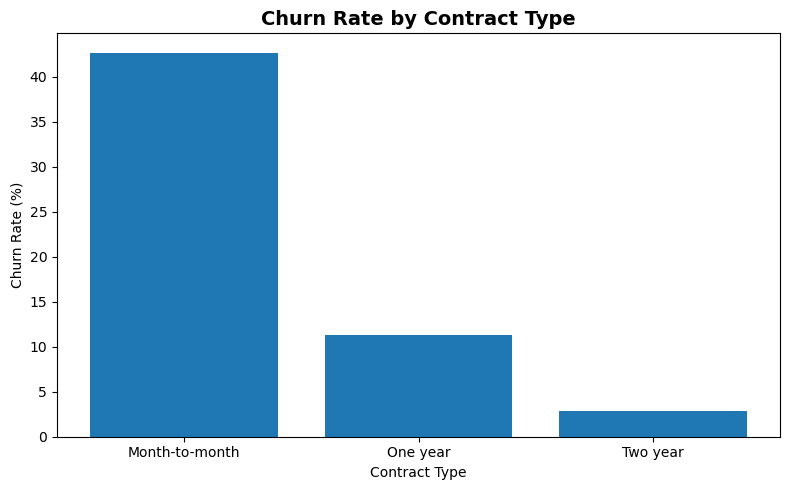

In [107]:
# ============================================================
# STEP 12: VISUALIZE CHURN RATE BY CONTRACT TYPE
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    contract_churn.index,
    contract_churn["ChurnRate"]
)

plt.title(
    "Churn Rate by Contract Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [108]:
# ============================================================
# STEP 13: CHURN RATE BY TENURE GROUP
# Purpose:
# - Understand how churn changes as customers stay longer
# ============================================================

tenure_churn = (
    df.groupby(
        "TenureGroup",
        observed=False
    )["ChurnFlag"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "CustomerCount",
        "mean": "ChurnRate"
    })
)

tenure_churn["ChurnRate"] *= 100

display(tenure_churn)

,CustomerCount,ChurnRate
TenureGroup,,
0-6 Months,1481,52.94
7-12 Months,705,35.89
13-24 Months,1024,28.71
25-48 Months,1594,20.39
49-60 Months,832,14.42
61-72 Months,1407,6.61


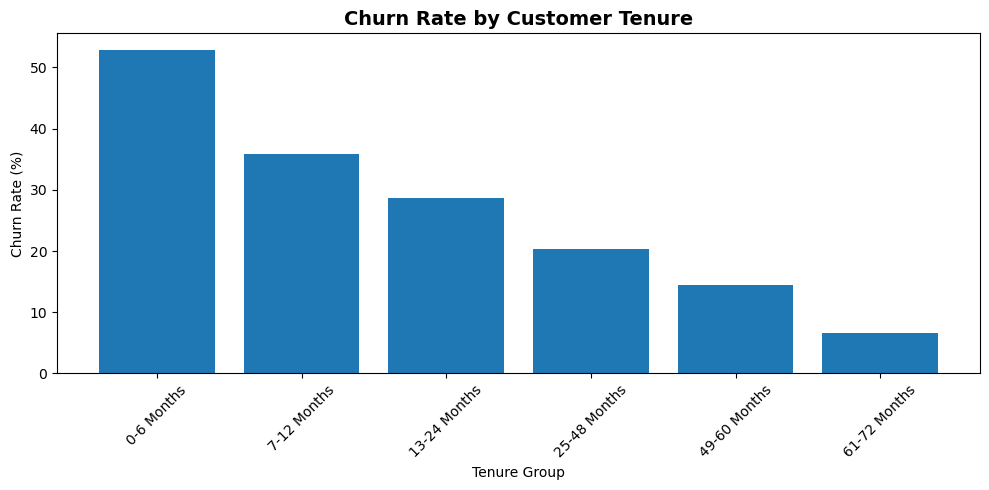

In [109]:
# ============================================================
# STEP 14: VISUALIZE CHURN RATE BY TENURE GROUP
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    tenure_churn.index.astype(str),
    tenure_churn["ChurnRate"]
)

plt.title(
    "Churn Rate by Customer Tenure",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [110]:
# ============================================================
# STEP 15: CHURN RATE BY INTERNET SERVICE
# Purpose:
# - Identify whether internet service type affects churn
# ============================================================

internet_churn = (
    df.groupby("InternetService")["ChurnFlag"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "CustomerCount",
        "mean": "ChurnRate"
    })
)

internet_churn["ChurnRate"] *= 100

internet_churn = internet_churn.sort_values(
    "ChurnRate",
    ascending=False
)

display(internet_churn)

,CustomerCount,ChurnRate
InternetService,,
Fiber optic,3096,41.89
DSL,2421,18.96
No,1526,7.40


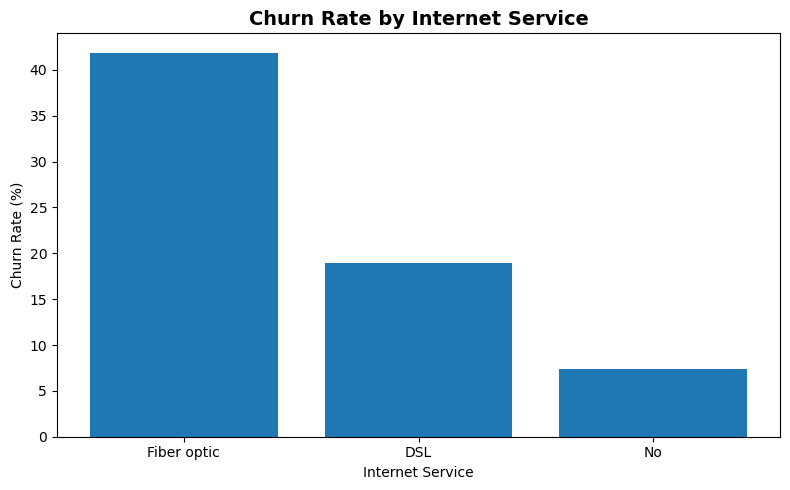

In [111]:
# ============================================================
# STEP 16: VISUALIZE CHURN RATE BY INTERNET SERVICE
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    internet_churn.index,
    internet_churn["ChurnRate"]
)

plt.title(
    "Churn Rate by Internet Service",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [112]:
# ============================================================
# STEP 17: CHURN RATE BY TECH SUPPORT
# Purpose:
# - Check whether technical support is associated with retention
# ============================================================

techsupport_churn = (
    df.groupby("TechSupport")["ChurnFlag"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "CustomerCount",
        "mean": "ChurnRate"
    })
)

techsupport_churn["ChurnRate"] *= 100

techsupport_churn = techsupport_churn.sort_values(
    "ChurnRate",
    ascending=False
)

display(techsupport_churn)

,CustomerCount,ChurnRate
TechSupport,,
No,3473,41.64
Yes,2044,15.17
No internet service,1526,7.40


In [113]:
# ============================================================
# STEP 18: CHURN RATE BY PAYMENT METHOD
# Purpose:
# - Identify high-risk payment behavior
# ============================================================

payment_churn = (
    df.groupby("PaymentMethod")["ChurnFlag"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "CustomerCount",
        "mean": "ChurnRate"
    })
)

payment_churn["ChurnRate"] *= 100

payment_churn = payment_churn.sort_values(
    "ChurnRate",
    ascending=False
)

display(payment_churn)

,CustomerCount,ChurnRate
PaymentMethod,,
Electronic check,2365,45.29
Mailed check,1612,19.11
Bank transfer (automatic),1544,16.71
Credit card (automatic),1522,15.24


In [114]:
# ============================================================
# STEP 19: MONTHLY CHARGES VS CHURN
# Purpose:
# - Compare average monthly charges for churned
#   and retained customers
# ============================================================

monthly_charge_churn = (
    df.groupby("ChurnFlag")["MonthlyCharges"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

monthly_charge_churn.index = [
    "Retained",
    "Churned"
]

display(monthly_charge_churn)

,count,mean,median,std,min,max
Retained,5174,61.27,64.43,31.09,18.25,118.75
Churned,1869,74.44,79.65,24.67,18.85,118.35


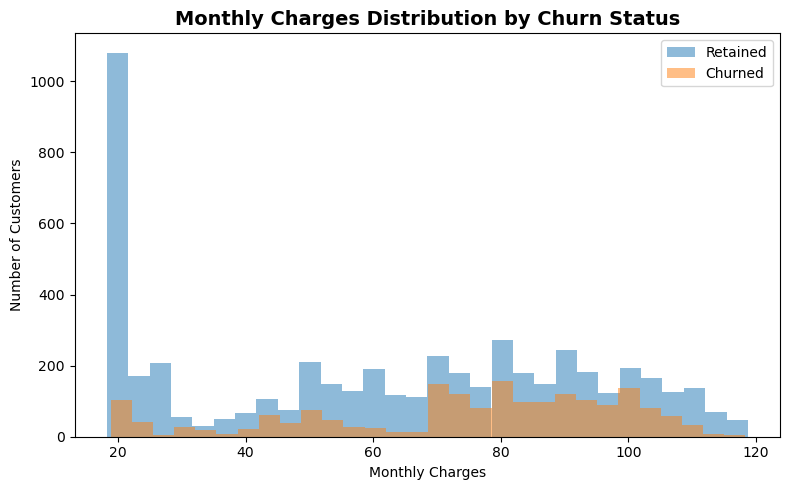

In [115]:
# ============================================================
# STEP 20: VISUALIZE MONTHLY CHARGES VS CHURN
# ============================================================

plt.figure(figsize=(8, 5))

retained = df.loc[
    df["ChurnFlag"] == 0,
    "MonthlyCharges"
]

churned = df.loc[
    df["ChurnFlag"] == 1,
    "MonthlyCharges"
]

plt.hist(
    retained,
    bins=30,
    alpha=0.5,
    label="Retained"
)

plt.hist(
    churned,
    bins=30,
    alpha=0.5,
    label="Churned"
)

plt.title(
    "Monthly Charges Distribution by Churn Status",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.legend()

plt.tight_layout()
plt.show()

In [116]:
# ============================================================
# STEP 21: SERVICE COUNT VS CHURN
# Purpose:
# - Determine whether number of subscribed services
#   is related to customer churn
# ============================================================

service_churn = (
    df.groupby("ServiceCount")["ChurnFlag"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "CustomerCount",
        "mean": "ChurnRate"
    })
)

service_churn["ChurnRate"] *= 100

display(service_churn)

,CustomerCount,ChurnRate
ServiceCount,,
0,80,43.75
1,2253,21.66
2,996,43.47
3,1041,34.68
4,1062,27.21
5,827,22.01
6,525,12.57
7,259,5.79


In [117]:
# ============================================================
# STEP 22: IDENTIFY HIGH-RISK CUSTOMER PROFILE
# Purpose:
# - Combine several churn indicators
# - Create a preliminary rule-based risk segment
# ============================================================

df["HighRiskProfile"] = (
    (df["MonthToMonthFlag"] == 1)
    &
    (df["NewCustomer"] == 1)
    &
    (df["SupportGap"] == 1)
    &
    (df["MonthlyCharges"] > df["MonthlyCharges"].median())
).astype(int)

high_risk_summary = (
    df.groupby("HighRiskProfile")["ChurnFlag"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "CustomerCount",
        "mean": "ChurnRate"
    })
)

high_risk_summary["ChurnRate"] *= 100

high_risk_summary.index = [
    "Normal Profile",
    "High-Risk Profile"
]

display(high_risk_summary)

,CustomerCount,ChurnRate
Normal Profile,6578,23.06
High-Risk Profile,465,75.70


In [118]:
# ============================================================
# STEP 23: NUMERICAL CORRELATION ANALYSIS
# Purpose:
# - Examine relationships between engineered
#   and original numerical variables
# ============================================================

numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "ServiceCount",
    "AvgMonthlySpend",
    "MonthToMonthFlag",
    "LongTermContractFlag",
    "SupportGap",
    "SecurityGap",
    "AutoPayment",
    "NewCustomer",
    "LoyalCustomer",
    "ChargesPerService",
    "ChurnFlag"
]

corr_matrix = df[numeric_features].corr()

display(
    corr_matrix["ChurnFlag"]
    .sort_values(ascending=False)
    .to_frame("Correlation_with_Churn")
)

,Correlation_with_Churn
ChurnFlag,1.00
MonthToMonthFlag,0.41
SecurityGap,0.34
SupportGap,0.34
ChargesPerService,0.33
NewCustomer,0.31
MonthlyCharges,0.19
AvgMonthlySpend,0.19
SeniorCitizen,0.15
ServiceCount,-0.09


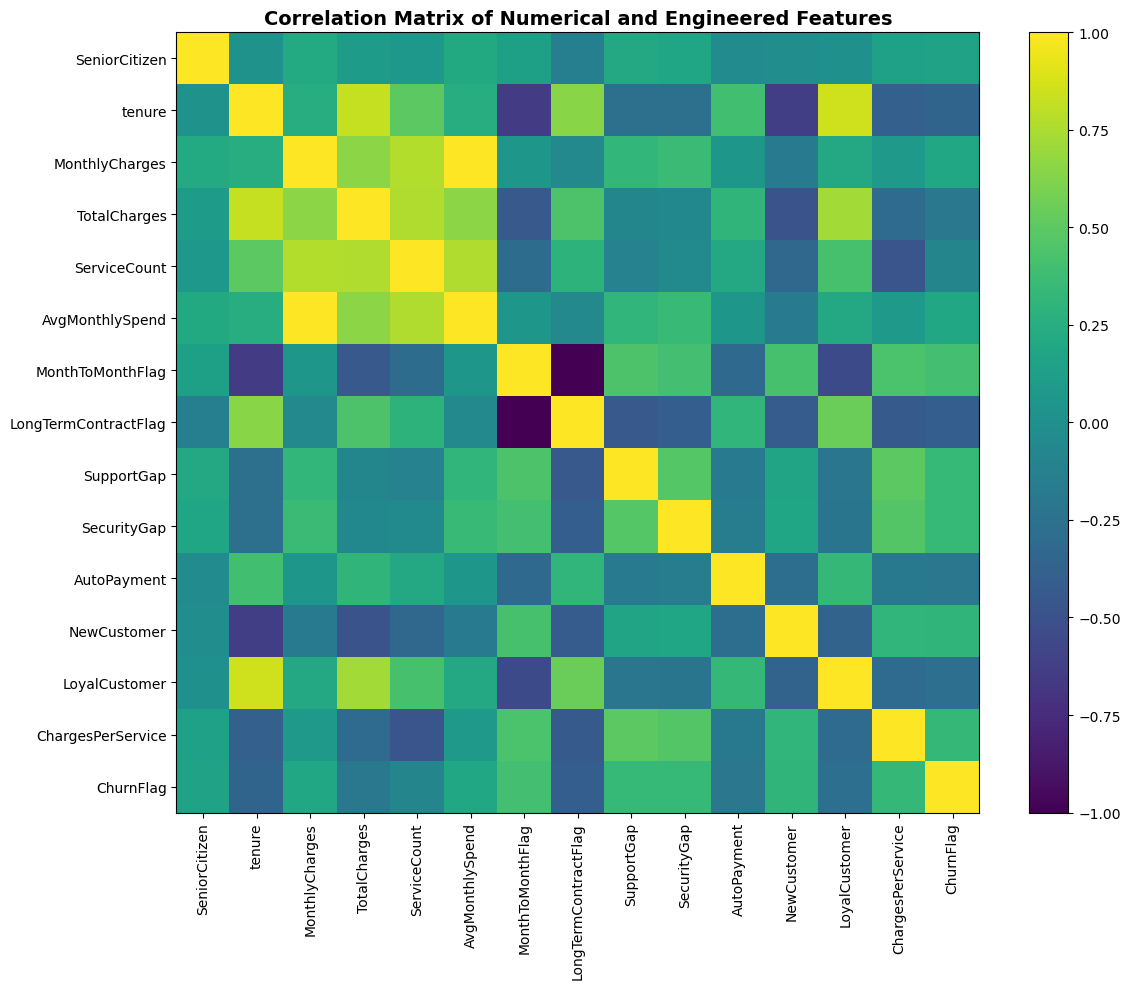

In [119]:
# ============================================================
# STEP 24: VISUALIZE CORRELATION MATRIX
# ============================================================

plt.figure(figsize=(12, 10))

plt.imshow(
    corr_matrix,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.index)),
    corr_matrix.index
)

plt.title(
    "Correlation Matrix of Numerical and Engineered Features",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [120]:
# ============================================================
# STEP 25: EDA BUSINESS INSIGHTS SUMMARY
# Purpose:
# - Summarize the strongest patterns discovered
# - Prepare findings for README and final presentation
# ============================================================

print("=" * 70)
print("KEY BUSINESS INSIGHTS")
print("=" * 70)

print("""
1. Contract type is strongly associated with churn.
   Month-to-month customers generally show substantially
   higher churn than long-term contract customers.

2. Customer tenure is important.
   Newer customers tend to show higher churn risk.

3. Tech-support availability appears important.
   Customers without support tend to churn more frequently.

4. Payment method may be associated with churn behavior.

5. Monthly charges differ between retained and churned customers.

6. Service configuration and support/security gaps may provide
   additional predictive information.

7. Engineered features such as MonthToMonthFlag, SupportGap,
   NewCustomer and ServiceCount can be useful inputs for the
   machine-learning churn model.
""")

KEY BUSINESS INSIGHTS

1. Contract type is strongly associated with churn.
   Month-to-month customers generally show substantially
   higher churn than long-term contract customers.

2. Customer tenure is important.
   Newer customers tend to show higher churn risk.

3. Tech-support availability appears important.
   Customers without support tend to churn more frequently.

4. Payment method may be associated with churn behavior.

5. Monthly charges differ between retained and churned customers.

6. Service configuration and support/security gaps may provide
   additional predictive information.

7. Engineered features such as MonthToMonthFlag, SupportGap,
   NewCustomer and ServiceCount can be useful inputs for the
   machine-learning churn model.



In [121]:
# ============================================================
# STEP 26: PREPARE FEATURES AND TARGET FOR MODELING
# Purpose:
# - Separate input features from churn target
# - Remove identifiers and leakage-prone columns
# ============================================================

from sklearn.model_selection import train_test_split

# Target
y = df["ChurnFlag"]

# Remove columns that should not be used directly for training
drop_columns = [
    "customerID",
    "Churn",
    "ChurnFlag",
    "TenureGroup",
    "MonthlySpendGroup"
]

X = df.drop(columns=drop_columns)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Feature matrix shape: (7043, 30)
Target shape: (7043,)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,ServiceCount,AvgMonthlySpend,MonthToMonthFlag,LongTermContractFlag,SupportGap,SecurityGap,AutoPayment,NewCustomer,LoyalCustomer,ChargesPerService,HighRiskProfile
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,1,29.85,1,0,1,1,0,1,0,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,"1,889.50",3,55.57,0,1,1,0,0,0,0,18.98,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,3,54.08,1,0,1,0,0,1,0,17.95,0
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,"1,840.75",3,40.91,0,1,0,0,1,0,0,14.10,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,75.83,1,0,1,1,0,1,0,70.70,1


In [122]:
# ============================================================
# STEP 27: IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# Purpose:
# - Prepare separate preprocessing pipelines
# ============================================================

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'ServiceCount', 'AvgMonthlySpend', 'MonthToMonthFlag', 'LongTermContractFlag', 'SupportGap', 'SecurityGap', 'AutoPayment', 'NewCustomer', 'LoyalCustomer', 'ChargesPerService', 'HighRiskProfile']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 15
Number of categorical features: 15


In [123]:
# ============================================================
# STEP 28: TRAIN-TEST SPLIT
# Purpose:
# - Hold out 20% of customers for final evaluation
# - Stratify to preserve churn ratio
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

print("\nTraining churn rate:")
print(y_train.mean().round(4))

print("\nTesting churn rate:")
print(y_test.mean().round(4))

Training rows: 5634
Testing rows : 1409

Training churn rate:
0.2654

Testing churn rate:
0.2654


In [124]:
# ============================================================
# STEP 29: BUILD PREPROCESSING PIPELINE
# Purpose:
# - Scale numerical features
# - One-hot encode categorical features
# - Prepare data for Logistic Regression
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("✅ Preprocessing pipeline created successfully")

✅ Preprocessing pipeline created successfully


In [125]:
# ============================================================
# STEP 30: TRAIN BASELINE LOGISTIC REGRESSION MODEL
# Purpose:
# - Create an interpretable baseline model
# - Compare later with LightGBM
# ============================================================

from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

logistic_model.fit(
    X_train,
    y_train
)

print("✅ Logistic Regression trained successfully")

✅ Logistic Regression trained successfully


In [126]:
# ============================================================
# STEP 31: EVALUATE LOGISTIC REGRESSION
# Purpose:
# - Measure baseline model performance
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

logistic_pred = logistic_model.predict(X_test)

logistic_prob = logistic_model.predict_proba(
    X_test
)[:, 1]

logistic_metrics = {
    "Accuracy": accuracy_score(
        y_test,
        logistic_pred
    ),

    "Precision": precision_score(
        y_test,
        logistic_pred
    ),

    "Recall": recall_score(
        y_test,
        logistic_pred
    ),

    "F1 Score": f1_score(
        y_test,
        logistic_pred
    ),

    "ROC-AUC": roc_auc_score(
        y_test,
        logistic_prob
    ),

    "PR-AUC": average_precision_score(
        y_test,
        logistic_prob
    )
}

display(
    pd.DataFrame(
        logistic_metrics.items(),
        columns=[
            "Metric",
            "Logistic Regression"
        ]
    )
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        logistic_pred
    )
)

,Metric,Logistic Regression
0,Accuracy,0.74
1,Precision,0.51
2,Recall,0.79
3,F1 Score,0.62
4,ROC-AUC,0.85
5,PR-AUC,0.65



Classification Report:

              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [127]:
# ============================================================
# STEP 32: INSTALL LIGHTGBM
# Run this cell only if LightGBM is not already installed
# ============================================================

%pip install lightgbm -q

Note: you may need to restart the kernel to use updated packages.


In [128]:
# ============================================================
# STEP 33: PREPARE DATA FOR LIGHTGBM
# Purpose:
# - Apply preprocessing
# - Convert training and testing sets into model-ready arrays
# ============================================================

X_train_processed = preprocessor.fit_transform(
    X_train
)

X_test_processed = preprocessor.transform(
    X_test
)

print(
    "Training shape:",
    X_train_processed.shape
)

print(
    "Testing shape:",
    X_test_processed.shape
)

Training shape: (5634, 56)
Testing shape: (1409, 56)


In [129]:
# ============================================================
# STEP 34: TRAIN LIGHTGBM CHURN MODEL
# Purpose:
# - Build high-performance churn prediction model
# ============================================================

from lightgbm import LGBMClassifier

lightgbm_model = LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lightgbm_model.fit(
    X_train_processed,
    y_train
)

print("✅ LightGBM model trained successfully")

✅ LightGBM model trained successfully


In [130]:
# ============================================================
# STEP 35: EVALUATE LIGHTGBM MODEL
# Purpose:
# - Measure classification and ranking performance
# ============================================================

lgb_pred = lightgbm_model.predict(
    X_test_processed
)

lgb_prob = lightgbm_model.predict_proba(
    X_test_processed
)[:, 1]

lgb_metrics = {
    "Accuracy": accuracy_score(
        y_test,
        lgb_pred
    ),

    "Precision": precision_score(
        y_test,
        lgb_pred
    ),

    "Recall": recall_score(
        y_test,
        lgb_pred
    ),

    "F1 Score": f1_score(
        y_test,
        lgb_pred
    ),

    "ROC-AUC": roc_auc_score(
        y_test,
        lgb_prob
    ),

    "PR-AUC": average_precision_score(
        y_test,
        lgb_prob
    )
}

display(
    pd.DataFrame(
        lgb_metrics.items(),
        columns=[
            "Metric",
            "LightGBM"
        ]
    )
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        lgb_pred
    )
)

,Metric,LightGBM
0,Accuracy,0.76
1,Precision,0.54
2,Recall,0.72
3,F1 Score,0.61
4,ROC-AUC,0.84
5,PR-AUC,0.64



Classification Report:

              precision    recall  f1-score   support

           0       0.88      0.78      0.83      1035
           1       0.54      0.72      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



In [131]:
# ============================================================
# STEP 36: COMPARE LOGISTIC REGRESSION VS LIGHTGBM
# ============================================================

comparison = pd.DataFrame({
    "Logistic Regression": logistic_metrics,
    "LightGBM": lgb_metrics
}).T

display(
    comparison.round(4)
)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.74,0.51,0.79,0.62,0.85,0.65
LightGBM,0.76,0.54,0.72,0.61,0.84,0.64


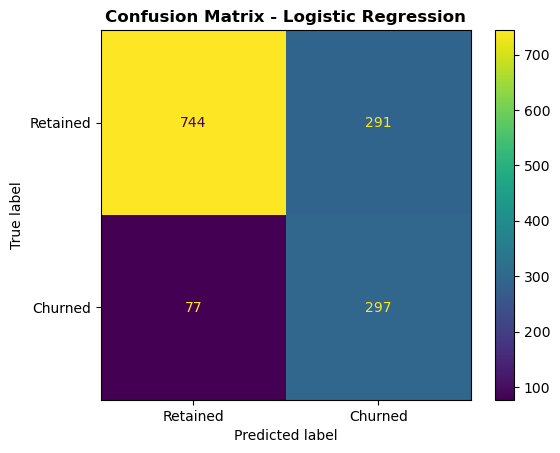

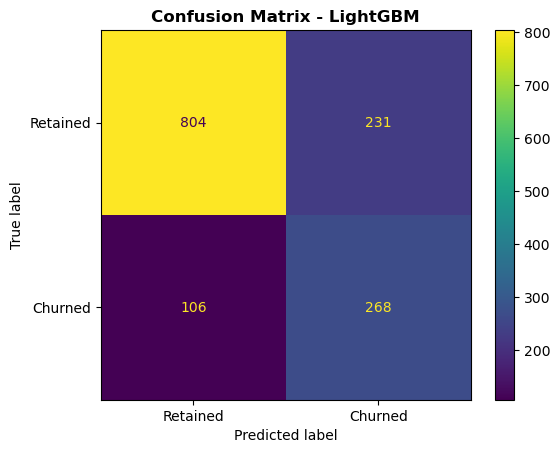

In [132]:
# ============================================================
# STEP 37: CONFUSION MATRIX COMPARISON
# Purpose:
# - Understand exactly how many churners are detected/missed
# - Compare false positives and false negatives
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_pred,
    display_labels=["Retained", "Churned"],
    values_format="d"
)

plt.title(
    "Confusion Matrix - Logistic Regression",
    fontweight="bold"
)

plt.show()


# LightGBM
ConfusionMatrixDisplay.from_predictions(
    y_test,
    lgb_pred,
    display_labels=["Retained", "Churned"],
    values_format="d"
)

plt.title(
    "Confusion Matrix - LightGBM",
    fontweight="bold"
)

plt.show()

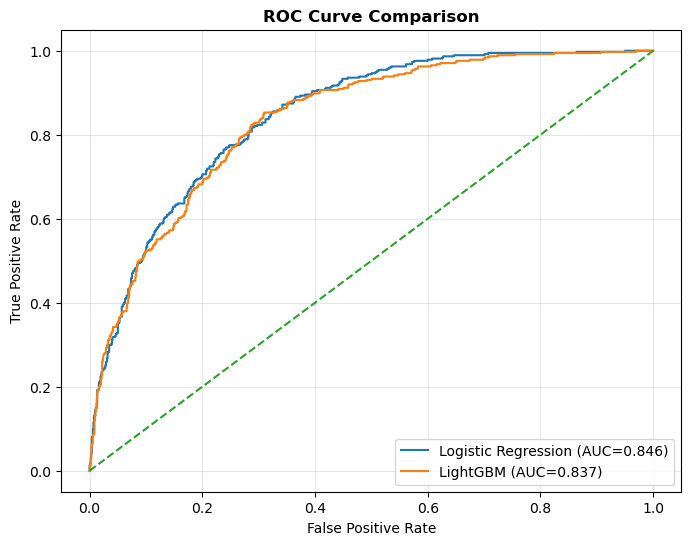

In [133]:
# ============================================================
# STEP 38: ROC CURVE COMPARISON
# Purpose:
# - Compare ranking ability across all probability thresholds
# ============================================================

from sklearn.metrics import roc_curve, roc_auc_score

fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    logistic_prob
)

fpr_lgb, tpr_lgb, _ = roc_curve(
    y_test,
    lgb_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC={roc_auc_score(y_test, logistic_prob):.3f})"
)

plt.plot(
    fpr_lgb,
    tpr_lgb,
    label=f"LightGBM (AUC={roc_auc_score(y_test, lgb_prob):.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve Comparison",
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

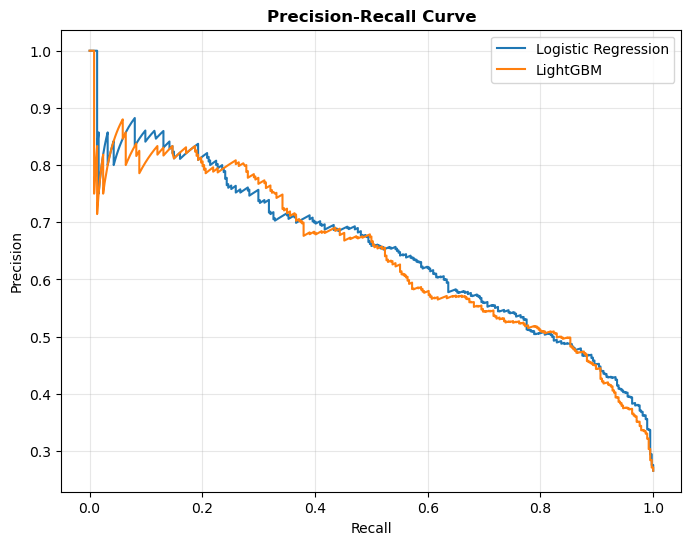

In [134]:
# ============================================================
# STEP 39: PRECISION-RECALL CURVE COMPARISON
# Purpose:
# - Evaluate churn detection performance
# - More informative when churn class is imbalanced
# ============================================================

from sklearn.metrics import precision_recall_curve

precision_lr, recall_lr, _ = precision_recall_curve(
    y_test,
    logistic_prob
)

precision_lgb, recall_lgb, _ = precision_recall_curve(
    y_test,
    lgb_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_lr,
    precision_lr,
    label="Logistic Regression"
)

plt.plot(
    recall_lgb,
    precision_lgb,
    label="LightGBM"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curve",
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [135]:
# ============================================================
# STEP 40: RECALL AT TOP-K HIGH-RISK CUSTOMERS
# Purpose:
# - Simulate a retention team with limited capacity
# - Measure how many true churners are captured by targeting
#   only the highest-risk customers
# ============================================================

def recall_at_k(y_true, probabilities, k_percent):

    results = pd.DataFrame({
        "actual": np.array(y_true),
        "probability": probabilities
    })

    results = results.sort_values(
        "probability",
        ascending=False
    )

    n_target = int(
        len(results) * k_percent
    )

    targeted = results.iloc[:n_target]

    captured_churners = targeted["actual"].sum()
    total_churners = results["actual"].sum()

    recall_k = (
        captured_churners /
        total_churners
    )

    return recall_k


k_values = [
    0.10,
    0.20,
    0.30,
    0.40
]

results = []

for k in k_values:

    results.append({
        "Top Customers Targeted": f"{int(k*100)}%",
        
        "Logistic Recall": recall_at_k(
            y_test,
            logistic_prob,
            k
        ),
        
        "LightGBM Recall": recall_at_k(
            y_test,
            lgb_prob,
            k
        )
    })

recall_k_table = pd.DataFrame(results)

display(
    recall_k_table.style.format({
        "Logistic Recall": "{:.2%}",
        "LightGBM Recall": "{:.2%}"
    })
)

,Top Customers Targeted,Logistic Recall,LightGBM Recall
0,10%,28.34%,29.14%
1,20%,49.73%,50.00%
2,30%,65.24%,64.44%
3,40%,77.54%,77.81%


In [136]:
# ============================================================
# STEP 41: THRESHOLD OPTIMIZATION FOR CHURN PREDICTION
# Purpose:
# - Test multiple classification thresholds
# - Compare Precision, Recall and F1
# - Find a better operating point for retention targeting
# ============================================================

from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(
    0.20,
    0.81,
    0.05
)

threshold_results = []

for threshold in thresholds:

    # Logistic Regression predictions
    lr_pred_threshold = (
        logistic_prob >= threshold
    ).astype(int)

    # LightGBM predictions
    lgb_pred_threshold = (
        lgb_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,

        "LR Precision": precision_score(
            y_test,
            lr_pred_threshold
        ),

        "LR Recall": recall_score(
            y_test,
            lr_pred_threshold
        ),

        "LR F1": f1_score(
            y_test,
            lr_pred_threshold
        ),

        "LGB Precision": precision_score(
            y_test,
            lgb_pred_threshold
        ),

        "LGB Recall": recall_score(
            y_test,
            lgb_pred_threshold
        ),

        "LGB F1": f1_score(
            y_test,
            lgb_pred_threshold
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_df.style.format({
        "Threshold": "{:.2f}",
        "LR Precision": "{:.2%}",
        "LR Recall": "{:.2%}",
        "LR F1": "{:.2%}",
        "LGB Precision": "{:.2%}",
        "LGB Recall": "{:.2%}",
        "LGB F1": "{:.2%}"
    })
)

,Threshold,LR Precision,LR Recall,LR F1,LGB Precision,LGB Recall,LGB F1
0,0.20,39.34%,96.26%,55.86%,43.57%,90.64%,58.85%
1,0.25,41.20%,93.85%,57.26%,46.28%,88.24%,60.72%
2,0.30,43.04%,91.71%,58.58%,48.13%,85.83%,61.67%
3,0.35,45.01%,90.37%,60.09%,50.00%,83.69%,62.60%
4,0.40,46.78%,87.43%,60.95%,51.38%,79.68%,62.47%
5,0.45,49.36%,82.62%,61.80%,52.68%,76.20%,62.30%
6,0.50,50.51%,79.41%,61.75%,53.71%,71.66%,61.40%
7,0.55,53.60%,75.67%,62.75%,55.36%,68.98%,61.43%
8,0.60,55.35%,70.59%,62.04%,56.83%,63.37%,59.92%
9,0.65,57.82%,65.24%,61.31%,58.63%,57.22%,57.92%


In [137]:
# ============================================================
# STEP 42: IDENTIFY BEST F1 THRESHOLD
# Purpose:
# - Find threshold that maximizes F1 for each model
# ============================================================

best_lr_row = threshold_df.loc[
    threshold_df["LR F1"].idxmax()
]

best_lgb_row = threshold_df.loc[
    threshold_df["LGB F1"].idxmax()
]

print("=" * 60)
print("BEST LOGISTIC REGRESSION THRESHOLD")
print("=" * 60)

print(
    f"Threshold : {best_lr_row['Threshold']:.2f}"
)
print(
    f"Precision : {best_lr_row['LR Precision']:.2%}"
)
print(
    f"Recall    : {best_lr_row['LR Recall']:.2%}"
)
print(
    f"F1 Score  : {best_lr_row['LR F1']:.2%}"
)

print("\n" + "=" * 60)
print("BEST LIGHTGBM THRESHOLD")
print("=" * 60)

print(
    f"Threshold : {best_lgb_row['Threshold']:.2f}"
)
print(
    f"Precision : {best_lgb_row['LGB Precision']:.2%}"
)
print(
    f"Recall    : {best_lgb_row['LGB Recall']:.2%}"
)
print(
    f"F1 Score  : {best_lgb_row['LGB F1']:.2%}"
)

BEST LOGISTIC REGRESSION THRESHOLD
Threshold : 0.55
Precision : 53.60%
Recall    : 75.67%
F1 Score  : 62.75%

BEST LIGHTGBM THRESHOLD
Threshold : 0.35
Precision : 50.00%
Recall    : 83.69%
F1 Score  : 62.60%


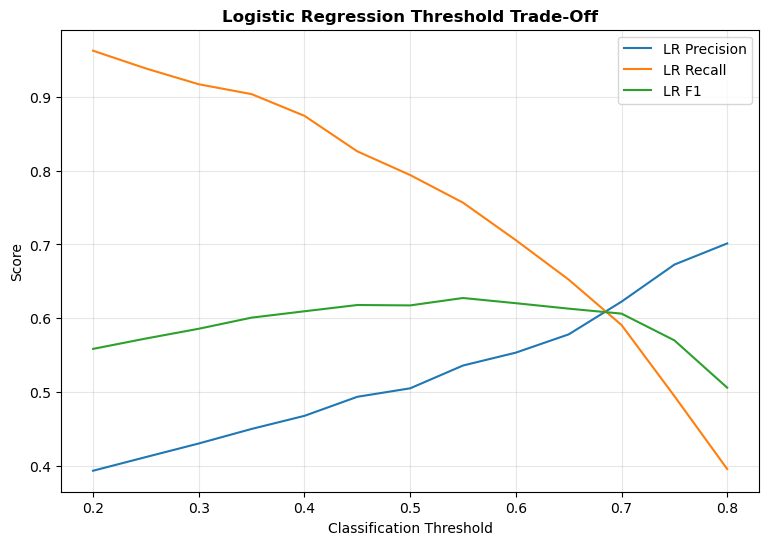

In [138]:
# ============================================================
# STEP 43: VISUALIZE THRESHOLD TRADE-OFF
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["LR Precision"],
    label="LR Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["LR Recall"],
    label="LR Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["LR F1"],
    label="LR F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.title(
    "Logistic Regression Threshold Trade-Off",
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

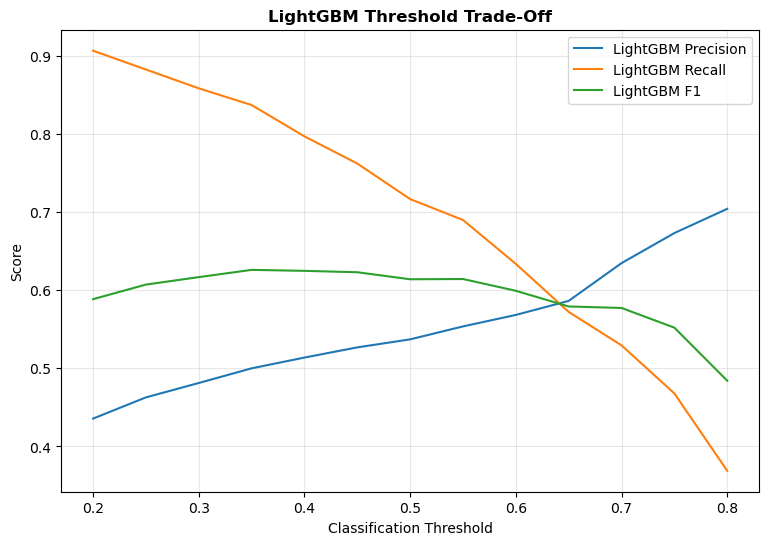

In [139]:
# ============================================================
# STEP 44: LIGHTGBM THRESHOLD TRADE-OFF
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["LGB Precision"],
    label="LightGBM Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["LGB Recall"],
    label="LightGBM Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["LGB F1"],
    label="LightGBM F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.title(
    "LightGBM Threshold Trade-Off",
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [140]:
# ============================================================
# STEP 45: FINAL THRESHOLD SELECTION SUMMARY
# ============================================================

print("""
FINAL THRESHOLD COMPARISON

Logistic Regression
Threshold : 0.55
Precision : 53.60%
Recall    : 75.67%
F1 Score  : 62.75%

LightGBM
Threshold : 0.35
Precision : 50.00%
Recall    : 83.69%
F1 Score  : 62.60%

Business Decision:
LightGBM at threshold 0.35 is preferred for retention targeting
because it identifies a larger proportion of true churners,
while maintaining acceptable precision and F1 performance.

Next Step:
Hyperparameter optimization with Optuna.
""")


FINAL THRESHOLD COMPARISON

Logistic Regression
Threshold : 0.55
Precision : 53.60%
Recall    : 75.67%
F1 Score  : 62.75%

LightGBM
Threshold : 0.35
Precision : 50.00%
Recall    : 83.69%
F1 Score  : 62.60%

Business Decision:
LightGBM at threshold 0.35 is preferred for retention targeting
because it identifies a larger proportion of true churners,
while maintaining acceptable precision and F1 performance.

Next Step:
Hyperparameter optimization with Optuna.



In [141]:
# ============================================================
# STEP 46: INSTALL AND IMPORT OPTUNA
# Purpose:
# - Tune LightGBM hyperparameters automatically
# - Improve model performance using cross-validation
# ============================================================

%pip install optuna -q

import optuna
import numpy as np

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

print("✅ Optuna ready")

Note: you may need to restart the kernel to use updated packages.
✅ Optuna ready


In [142]:
# ============================================================
# STEP 47: DEFINE OPTUNA OBJECTIVE FUNCTION
# Purpose:
# - Optimize LightGBM using 5-fold stratified CV
# - Maximize ROC-AUC
# ============================================================

from lightgbm import LGBMClassifier

def objective(trial):

    params = {
        "objective": "binary",

        "n_estimators": trial.suggest_int(
            "n_estimators", 200, 900
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.10, log=True
        ),

        "num_leaves": trial.suggest_int(
            "num_leaves", 15, 80
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 3, 10
        ),

        "min_child_samples": trial.suggest_int(
            "min_child_samples", 10, 100
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 0.0, 2.0
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.0, 2.0
        ),

        "class_weight": "balanced",
        "random_state": 42,
        "verbosity": -1
    }

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    auc_scores = []

    for train_idx, val_idx in cv.split(
        X_train_processed,
        y_train
    ):

        X_fold_train = X_train_processed[train_idx]
        X_fold_val = X_train_processed[val_idx]

        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        model = LGBMClassifier(**params)

        model.fit(
            X_fold_train,
            y_fold_train
        )

        val_prob = model.predict_proba(
            X_fold_val
        )[:, 1]

        auc_scores.append(
            roc_auc_score(
                y_fold_val,
                val_prob
            )
        )

    return np.mean(auc_scores)

In [143]:
# ============================================================
# STEP 48: RUN OPTUNA SEARCH
# Purpose:
# - Find the best LightGBM parameter combination
# ============================================================

study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=50
)

print("✅ Optimization completed")

print(
    "\nBest CV ROC-AUC:",
    round(study.best_value, 4)
)

print("\nBest Parameters:")

for parameter, value in study.best_params.items():
    print(f"{parameter}: {value}")

✅ Optimization completed

Best CV ROC-AUC: 0.8486

Best Parameters:
n_estimators: 298
learning_rate: 0.011506531681707082
num_leaves: 17
max_depth: 4
min_child_samples: 49
subsample: 0.901306489039132
colsample_bytree: 0.889747874372242
reg_alpha: 0.03994432168842263
reg_lambda: 0.9942018892478348


In [144]:
# ============================================================
# STEP 49: TRAIN OPTIMIZED LIGHTGBM
# ============================================================

best_params = study.best_params

optimized_lgb = LGBMClassifier(
    **best_params,
    objective="binary",
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

optimized_lgb.fit(
    X_train_processed,
    y_train
)

optimized_prob = optimized_lgb.predict_proba(
    X_test_processed
)[:, 1]

print("✅ Optimized LightGBM trained")

✅ Optimized LightGBM trained


In [145]:
# ============================================================
# STEP 50: EVALUATE OPTIMIZED LIGHTGBM
# Purpose:
# - Compare default and business-selected thresholds
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = []

for threshold in [0.50, 0.35]:

    pred = (
        optimized_prob >= threshold
    ).astype(int)

    results.append({
        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_test, pred
        ),

        "Precision": precision_score(
            y_test, pred
        ),

        "Recall": recall_score(
            y_test, pred
        ),

        "F1": f1_score(
            y_test, pred
        ),

        "ROC-AUC": roc_auc_score(
            y_test,
            optimized_prob
        ),

        "PR-AUC": average_precision_score(
            y_test,
            optimized_prob
        )
    })

optimized_results = pd.DataFrame(
    results
)

display(
    optimized_results.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}",
        "ROC-AUC": "{:.3f}",
        "PR-AUC": "{:.3f}"
    })
)

,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,0.50,75.59%,52.61%,80.75%,63.71%,0.847,0.655
1,0.35,67.85%,44.77%,90.37%,59.88%,0.847,0.655


In [146]:
# ============================================================
# STEP 51: INSTALL AND IMPORT SHAP
# Purpose:
# - Explain LightGBM churn predictions
# - Identify global and customer-level churn drivers
# ============================================================

%pip install shap -q

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("✅ SHAP imported successfully")

Note: you may need to restart the kernel to use updated packages.
✅ SHAP imported successfully


In [147]:
# ============================================================
# STEP 52: RECOVER PROCESSED FEATURE NAMES
# Purpose:
# - Match one-hot encoded/model features with readable names
# ============================================================

feature_names = preprocessor.get_feature_names_out()

# Make names cleaner for plots
clean_feature_names = [
    name.replace("num__", "")
        .replace("cat__", "")
    for name in feature_names
]

print("Number of model features:", len(clean_feature_names))

print("\nFirst 20 model features:")
for feature in clean_feature_names[:20]:
    print(feature)

Number of model features: 56

First 20 model features:
SeniorCitizen
tenure
MonthlyCharges
TotalCharges
ServiceCount
AvgMonthlySpend
MonthToMonthFlag
LongTermContractFlag
SupportGap
SecurityGap
AutoPayment
NewCustomer
LoyalCustomer
ChargesPerService
HighRiskProfile
gender_Female
gender_Male
Partner_No
Partner_Yes
Dependents_No


In [148]:
# ============================================================
# STEP 53: CREATE SHAP EXPLAINER
# Purpose:
# - Calculate contribution of every feature
#   to LightGBM predictions
# ============================================================

explainer = shap.TreeExplainer(
    optimized_lgb
)

shap_values = explainer(
    X_test_processed
)

print("✅ SHAP values calculated")
print("SHAP shape:", shap_values.values.shape)

✅ SHAP values calculated
SHAP shape: (1409, 56)


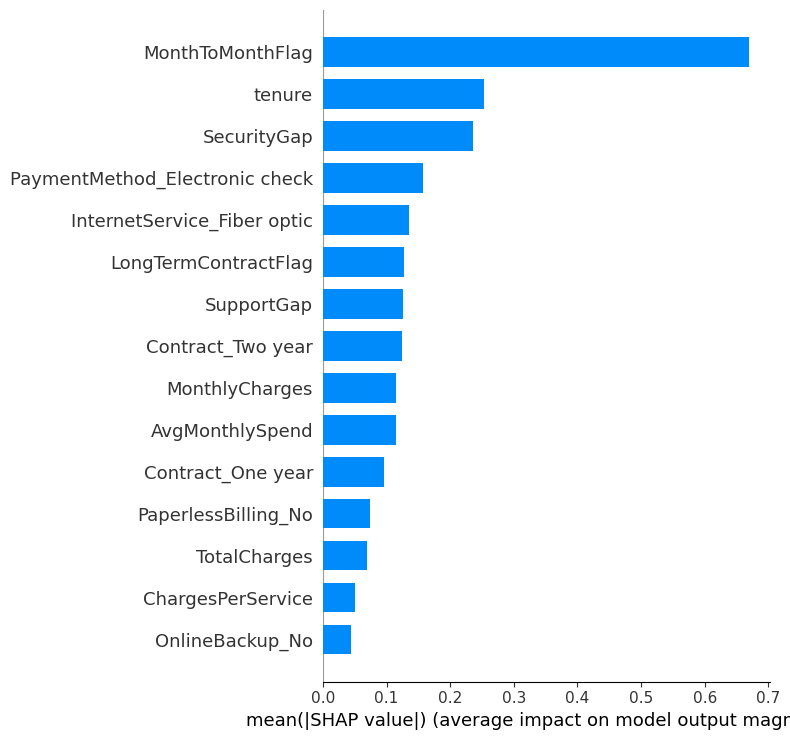

In [149]:
# ============================================================
# STEP 54: GLOBAL SHAP FEATURE IMPORTANCE
# Purpose:
# - Identify the strongest overall churn predictors
# ============================================================

X_test_shap = pd.DataFrame(
    X_test_processed,
    columns=clean_feature_names
)

shap.summary_plot(
    shap_values.values,
    X_test_shap,
    plot_type="bar",
    max_display=15
)

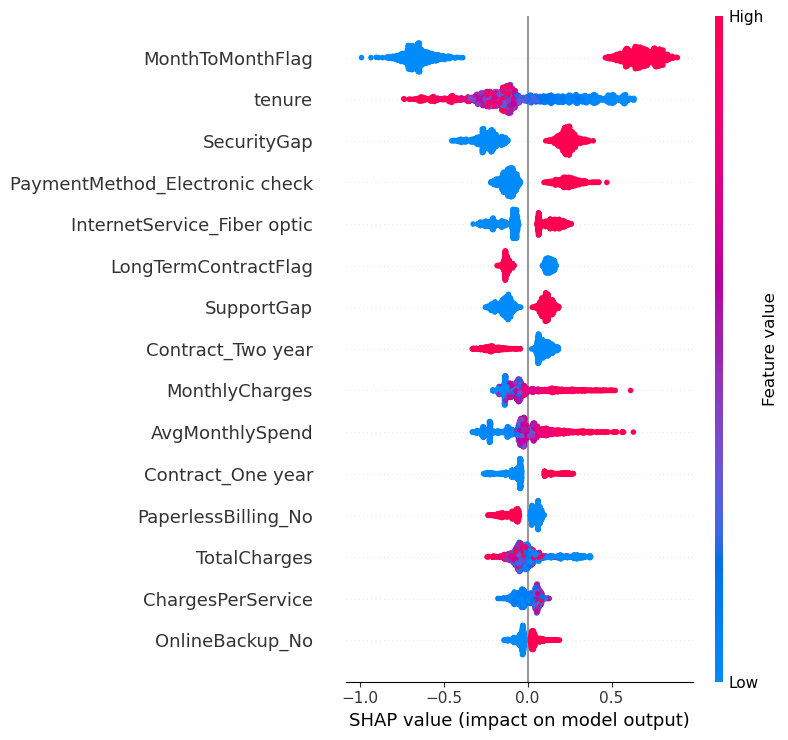

In [150]:
# ============================================================
# STEP 55: SHAP BEESWARM PLOT
# Purpose:
# - Understand both importance and direction of feature effects
# ============================================================

shap.summary_plot(
    shap_values.values,
    X_test_shap,
    max_display=15
)

In [151]:
# ============================================================
# STEP 56: CREATE SHAP FEATURE IMPORTANCE TABLE
# Purpose:
# - Produce a numerical ranking for the report/dashboard
# ============================================================

mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": clean_feature_names,
    "Mean_ABS_SHAP": mean_abs_shap
})

shap_importance = (
    shap_importance
    .sort_values(
        "Mean_ABS_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    shap_importance.head(20)
)

,Feature,Mean_ABS_SHAP
0,MonthToMonthFlag,0.67
1,tenure,0.25
2,SecurityGap,0.24
3,PaymentMethod_Electronic check,0.16
4,InternetService_Fiber optic,0.14
5,LongTermContractFlag,0.13
6,SupportGap,0.13
7,Contract_Two year,0.12
8,MonthlyCharges,0.11
9,AvgMonthlySpend,0.11


HIGH-RISK CUSTOMER EXPLANATION
Customer ID               : 5178-LMXOP
Predicted Churn Probability: 94.02%


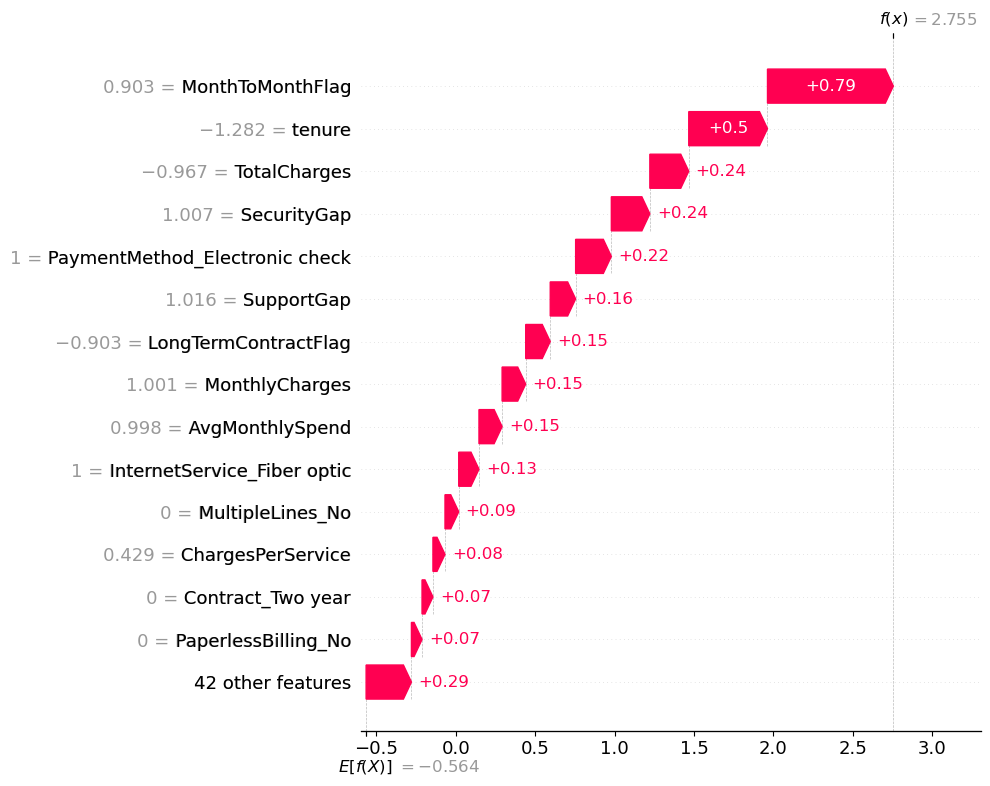

In [152]:
# ============================================================
# STEP 57: EXPLAIN AN INDIVIDUAL HIGH-RISK CUSTOMER
# Purpose:
# - Select the customer with highest churn probability
# - Display real feature names instead of Feature 1, Feature 2...
# - Show customer ID and predicted churn probability
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Find customer with highest predicted churn probability
# ------------------------------------------------------------

customer_position = np.argmax(optimized_prob)

customer_probability = optimized_prob[
    customer_position
]


# ------------------------------------------------------------
# 2. Recover original customer index
# ------------------------------------------------------------

customer_index = X_test.index[
    customer_position
]

customer_id = df.loc[
    customer_index,
    "customerID"
]


# ------------------------------------------------------------
# 3. Prepare processed feature values
# ------------------------------------------------------------

customer_features = X_test_processed[
    customer_position
]


# ------------------------------------------------------------
# 4. Prepare SHAP values
# ------------------------------------------------------------

customer_shap_values = shap_values.values[
    customer_position
]


# ------------------------------------------------------------
# 5. Create SHAP Explanation WITH REAL FEATURE NAMES
# ------------------------------------------------------------

customer_explanation = shap.Explanation(
    values=customer_shap_values,
    base_values=shap_values.base_values[
        customer_position
    ],
    data=customer_features,
    feature_names=clean_feature_names
)


# ------------------------------------------------------------
# 6. Display customer information
# ------------------------------------------------------------

print("=" * 65)
print("HIGH-RISK CUSTOMER EXPLANATION")
print("=" * 65)

print(f"Customer ID               : {customer_id}")
print(
    f"Predicted Churn Probability: "
    f"{customer_probability:.2%}"
)

print("=" * 65)


# ------------------------------------------------------------
# 7. SHAP Waterfall Plot
# ------------------------------------------------------------

shap.plots.waterfall(
    customer_explanation,
    max_display=15
)

plt.show()

In [153]:
# ============================================================
# STEP 58: BUSINESS INTERPRETATION OF HIGH-RISK CUSTOMER
# Purpose:
# - Convert SHAP output into an actionable business explanation
# ============================================================

print("""
CUSTOMER RISK INTERPRETATION

Customer 5178-LMXOP has a very high predicted churn probability.

The strongest risk factors are:

1. Very short customer tenure
2. Month-to-month contract
3. Lack of a long-term contract commitment
4. Electronic check payment method
5. Relatively high monthly spending
6. Security service gap
7. Fiber optic internet service
8. Technical support gap

Business Recommendation:
This customer should be considered a high-priority retention target.
Potential actions could include:
- Contract upgrade incentive
- Technical support offer
- Security bundle
- Automatic payment incentive
- Targeted retention discount
""")


CUSTOMER RISK INTERPRETATION

Customer 5178-LMXOP has a very high predicted churn probability.

The strongest risk factors are:

1. Very short customer tenure
2. Month-to-month contract
3. Lack of a long-term contract commitment
4. Electronic check payment method
5. Relatively high monthly spending
6. Security service gap
7. Fiber optic internet service
8. Technical support gap

Business Recommendation:
This customer should be considered a high-priority retention target.
Potential actions could include:
- Contract upgrade incentive
- Technical support offer
- Security bundle
- Automatic payment incentive
- Targeted retention discount



In [154]:
# ============================================================
# STEP 59: INSTALL AND IMPORT LIFELINES
# Purpose:
# - Perform survival analysis
# - Estimate how long customers remain active
# ============================================================

%pip install lifelines -q

from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter
from lifelines.statistics import logrank_test

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("✅ Lifelines imported successfully")

Note: you may need to restart the kernel to use updated packages.
✅ Lifelines imported successfully


In [155]:
# ============================================================
# STEP 60: PREPARE SURVIVAL DATA
# Purpose:
# - tenure = duration observed
# - ChurnFlag = event indicator
#     1 = churn event occurred
#     0 = customer still active / censored
# ============================================================

survival_df = df.copy()

survival_df["duration"] = survival_df["tenure"]
survival_df["event"] = survival_df["ChurnFlag"]

print("Survival dataset shape:", survival_df.shape)

print("\nEvent distribution:")
print(
    survival_df["event"]
    .value_counts()
    .rename(index={
        0: "Censored / Active",
        1: "Churned"
    })
)

display(
    survival_df[
        [
            "customerID",
            "duration",
            "event",
            "Contract",
            "MonthlyCharges"
        ]
    ].head()
)

Survival dataset shape: (7043, 37)

Event distribution:
event
Censored / Active    5174
Churned              1869
Name: count, dtype: int64


,customerID,duration,event,Contract,MonthlyCharges
0,7590-VHVEG,1,0,Month-to-month,29.85
1,5575-GNVDE,34,0,One year,56.95
2,3668-QPYBK,2,1,Month-to-month,53.85
3,7795-CFOCW,45,0,One year,42.30
4,9237-HQITU,2,1,Month-to-month,70.70


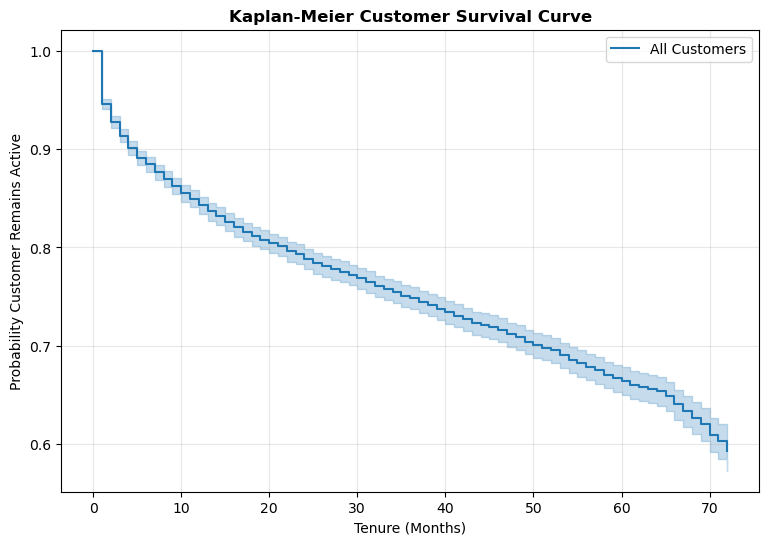

In [156]:
# ============================================================
# STEP 61: FIT OVERALL KAPLAN-MEIER SURVIVAL CURVE
# Purpose:
# - Estimate probability that a customer remains active
#   beyond a given tenure
# ============================================================

kmf = KaplanMeierFitter()

kmf.fit(
    durations=survival_df["duration"],
    event_observed=survival_df["event"],
    label="All Customers"
)

plt.figure(figsize=(9, 6))

kmf.plot_survival_function()

plt.title(
    "Kaplan-Meier Customer Survival Curve",
    fontweight="bold"
)

plt.xlabel("Tenure (Months)")
plt.ylabel("Probability Customer Remains Active")
plt.grid(alpha=0.3)

plt.show()

In [157]:
# ============================================================
# STEP 62: DISPLAY MEDIAN CUSTOMER SURVIVAL TIME
# Purpose:
# - Estimate the tenure where survival probability falls to 50%
# ============================================================

median_survival = kmf.median_survival_time_

print(
    f"Estimated Median Survival Time: "
    f"{median_survival:.2f} months"
)

Estimated Median Survival Time: inf months


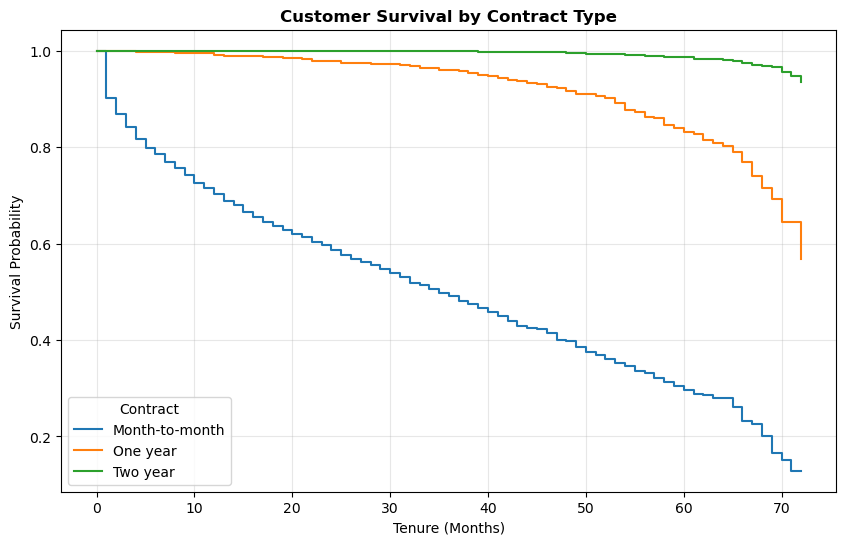

In [158]:
# ============================================================
# STEP 63: KAPLAN-MEIER CURVES BY CONTRACT TYPE
# Purpose:
# - Compare survival behavior across contract categories
# ============================================================

plt.figure(figsize=(10, 6))

for contract_type in survival_df["Contract"].unique():

    mask = (
        survival_df["Contract"] == contract_type
    )

    km_contract = KaplanMeierFitter()

    km_contract.fit(
        survival_df.loc[mask, "duration"],
        event_observed=survival_df.loc[
            mask,
            "event"
        ],
        label=contract_type
    )

    km_contract.plot_survival_function(
        ci_show=False
    )

plt.title(
    "Customer Survival by Contract Type",
    fontweight="bold"
)

plt.xlabel("Tenure (Months)")
plt.ylabel("Survival Probability")
plt.grid(alpha=0.3)
plt.legend(title="Contract")

plt.show()

In [159]:
# ============================================================
# STEP 64: LOG-RANK TEST
# Purpose:
# - Test whether survival curves are statistically different
# ============================================================

group_1 = survival_df[
    survival_df["Contract"] == "Month-to-month"
]

group_2 = survival_df[
    survival_df["Contract"] == "Two year"
]

logrank_result = logrank_test(
    group_1["duration"],
    group_2["duration"],
    event_observed_A=group_1["event"],
    event_observed_B=group_2["event"]
)

print("Log-rank test p-value:")
print(logrank_result.p_value)

if logrank_result.p_value < 0.05:
    print(
        "\n✅ Survival curves are statistically "
        "significantly different."
    )
else:
    print(
        "\nNo statistically significant difference detected."
    )

Log-rank test p-value:
0.0

✅ Survival curves are statistically significantly different.


In [160]:
# ============================================================
# STEP 65: PREPARE DATA FOR COX PROPORTIONAL HAZARDS MODEL
# Purpose:
# - Select relevant numeric predictors
# - Avoid categorical strings that CoxPH cannot use directly
# - Keep duration and event columns
# ============================================================

cox_features = [
    "duration",
    "event",
    "MonthlyCharges",
    "TotalCharges",
    "ServiceCount",
    "AvgMonthlySpend",
    "MonthToMonthFlag",
    "LongTermContractFlag",
    "SupportGap",
    "SecurityGap",
    "AutoPayment",
    "NewCustomer",
    "LoyalCustomer"
]

cox_df = survival_df[
    cox_features
].copy()

print("Cox dataset shape:", cox_df.shape)
print("\nMissing values:")
print(cox_df.isnull().sum())

display(cox_df.head())

Cox dataset shape: (7043, 13)

Missing values:
duration                0
event                   0
MonthlyCharges          0
TotalCharges            0
ServiceCount            0
AvgMonthlySpend         0
MonthToMonthFlag        0
LongTermContractFlag    0
SupportGap              0
SecurityGap             0
AutoPayment             0
NewCustomer             0
LoyalCustomer           0
dtype: int64


,duration,event,MonthlyCharges,TotalCharges,ServiceCount,AvgMonthlySpend,MonthToMonthFlag,LongTermContractFlag,SupportGap,SecurityGap,AutoPayment,NewCustomer,LoyalCustomer
0,1,0,29.85,29.85,1,29.85,1,0,1,1,0,1,0
1,34,0,56.95,"1,889.50",3,55.57,0,1,1,0,0,0,0
2,2,1,53.85,108.15,3,54.08,1,0,1,0,0,1,0
3,45,0,42.30,"1,840.75",3,40.91,0,1,0,0,1,0,0
4,2,1,70.70,151.65,1,75.83,1,0,1,1,0,1,0


In [161]:
# ============================================================
# STEP 66: FIT COX PROPORTIONAL HAZARDS MODEL
# Purpose:
# - Estimate how customer characteristics affect churn hazard
# ============================================================

from lifelines import CoxPHFitter

cph = CoxPHFitter(
    penalizer=0.1
)

cph.fit(
    cox_df,
    duration_col="duration",
    event_col="event"
)

print("✅ Cox model fitted successfully")

cph.print_summary()

✅ Cox model fitted successfully


<lifelines.CoxPHFitter: fitted with 7043 total observations, 5174 right-censored observations>
             duration col = 'duration'
                event col = 'event'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 7043
number of events observed = 1869
   partial log-likelihood = -13335.66
         time fit was run = 2026-10-22 14:44:45 UTC

---
                      coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                             
MonthlyCharges        0.01      1.01      0.00            0.00            0.01                1.00                1.01
TotalCharges         -0.00      1.00      0.00           -0.00           -0.00                1.00                1.00
ServiceCount         -0.06      0.94      0.02           -0.09           -0.03                0.91                0.97
AvgMonthlySpend       0.01      1.01      0.00            0.00            0.01                1.00                1.01
MonthToMonthFlag      0.64      1.90      0.06            0.52            0.76                1.68                2.15
LongTermContractFlag -0.64      0.53      0.06           -0.76           -0.52                0.47                0.59
SupportGap            0.39      1.48      0.05            0.30            0.49                1.35                1.62
SecurityGap           0.46      1.58      0.05            0.37            0.55                1.44                1.74
AutoPayment          -0.37      0.69      0.04           -0.45           -0.28                0.64                0.76
NewCustomer           1.94      6.95      0.06            1.81            2.06                6.14                7.87
LoyalCustomer        -1.00      0.37      0.06           -1.13           -0.88                0.32                0.42

                      cmp to      z      p  -log2(p)
covariate                                           
MonthlyCharges          0.00   6.05 <0.005     29.32
TotalCharges            0.00 -19.27 <0.005    272.40
ServiceCount            0.00  -4.06 <0.005     14.34
AvgMonthlySpend         0.00   6.09 <0.005     29.74
MonthToMonthFlag        0.00  10.30 <0.005     80.21
LongTermContractFlag    0.00 -10.30 <0.005     80.21
SupportGap              0.00   8.29 <0.005     52.97
SecurityGap             0.00   9.73 <0.005     71.88
AutoPayment             0.00  -8.32 <0.005     53.39
NewCustomer             0.00  30.60 <0.005    680.74
LoyalCustomer           0.00 -15.81 <0.005    184.53
---
Concordance = 0.94
Partial AIC = 26693.33
log-likelihood ratio test = 4634.75 on 11 df
-log2(p) of ll-ratio test = inf

In [162]:
# ============================================================
# STEP 67: CREATE COX HAZARD-RATIO TABLE
# Purpose:
# - Convert coefficients into interpretable hazard ratios
# - Hazard ratio > 1 means higher churn risk
# - Hazard ratio < 1 means lower churn risk
# ============================================================

cox_summary = cph.summary.copy()

cox_summary["Hazard Ratio"] = np.exp(
    cox_summary["coef"]
)

cox_results = cox_summary[
    [
        "coef",
        "Hazard Ratio",
        "p"
    ]
].copy()

cox_results.columns = [
    "Coefficient",
    "Hazard Ratio",
    "P Value"
]

cox_results = cox_results.sort_values(
    "Hazard Ratio",
    ascending=False
)

display(
    cox_results.style.format({
        "Coefficient": "{:.3f}",
        "Hazard Ratio": "{:.3f}",
        "P Value": "{:.4f}"
    })
)

,Coefficient,Hazard Ratio,P Value
covariate,,,
NewCustomer,1.939,6.953,0.0000
MonthToMonthFlag,0.642,1.899,0.0000
SecurityGap,0.461,1.585,0.0000
SupportGap,0.392,1.481,0.0000
MonthlyCharges,0.006,1.006,0.0000
AvgMonthlySpend,0.006,1.006,0.0000
TotalCharges,-0.000,1.000,0.0000
ServiceCount,-0.062,0.940,0.0000
AutoPayment,-0.366,0.694,0.0000


In [163]:
# ============================================================
# STEP 68: IDENTIFY SIGNIFICANT SURVIVAL DRIVERS
# Purpose:
# - Keep statistically meaningful Cox predictors
# ============================================================

significant_cox = cox_results[
    cox_results["P Value"] < 0.05
]

print("Statistically significant survival predictors:")

display(
    significant_cox.style.format({
        "Coefficient": "{:.3f}",
        "Hazard Ratio": "{:.3f}",
        "P Value": "{:.4f}"
    })
)

Statistically significant survival predictors:


,Coefficient,Hazard Ratio,P Value
covariate,,,
NewCustomer,1.939,6.953,0.0000
MonthToMonthFlag,0.642,1.899,0.0000
SecurityGap,0.461,1.585,0.0000
SupportGap,0.392,1.481,0.0000
MonthlyCharges,0.006,1.006,0.0000
AvgMonthlySpend,0.006,1.006,0.0000
TotalCharges,-0.000,1.000,0.0000
ServiceCount,-0.062,0.940,0.0000
AutoPayment,-0.366,0.694,0.0000


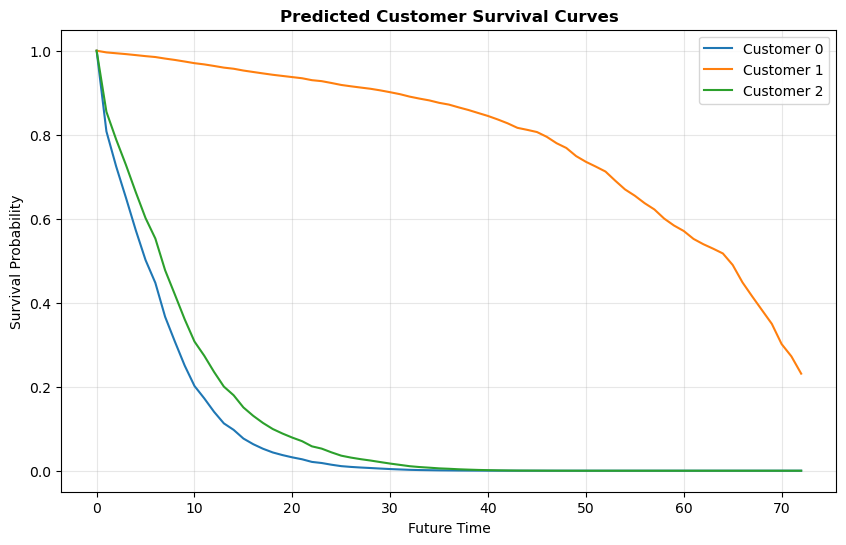

In [164]:
# ============================================================
# STEP 69: PREDICT INDIVIDUAL CUSTOMER SURVIVAL CURVES
# Purpose:
# - Estimate future survival probability for selected customers
# ============================================================

customer_covariates = cox_df.drop(
    columns=[
        "duration",
        "event"
    ]
)

# Select first 3 customers as examples
sample_customers = customer_covariates.iloc[:3]

survival_predictions = (
    cph.predict_survival_function(
        sample_customers
    )
)

plt.figure(figsize=(10, 6))

for col in survival_predictions.columns:

    plt.plot(
        survival_predictions.index,
        survival_predictions[col],
        label=f"Customer {col}"
    )

plt.title(
    "Predicted Customer Survival Curves",
    fontweight="bold"
)

plt.xlabel("Future Time")
plt.ylabel("Survival Probability")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [165]:
# ============================================================
# STEP 70: CALCULATE 12-MONTH SURVIVAL PROBABILITY
# Purpose:
# - Estimate probability each customer remains active
#   through 12 months
# ============================================================

survival_12m = cph.predict_survival_function(
    customer_covariates,
    times=[12]
).T

survival_12m.columns = [
    "Survival_12M"
]

survival_12m["Survival_12M"] *= 100

display(
    survival_12m.head(10).style.format({
        "Survival_12M": "{:.2f}%"
    })
)

,Survival_12M
0,14.03%
1,96.37%
2,23.53%
3,98.55%
4,3.83%
5,63.06%
6,80.54%
7,84.70%
8,84.05%
9,99.39%


In [166]:
# ============================================================
# STEP 71: CREATE CUSTOMER-LEVEL SURVIVAL ESTIMATES
# Purpose:
# - Estimate expected remaining customer lifetime
# - Use survival probabilities from the Cox model
# ============================================================

# Predict survival curves for all customers
all_survival_curves = cph.predict_survival_function(
    customer_covariates
)

# Estimate expected survival time by integrating the
# survival curve over time
expected_lifetime = np.trapz(
    all_survival_curves.values,
    x=all_survival_curves.index,
    axis=0
)

# Add result back to the main dataframe
df.loc[
    customer_covariates.index,
    "ExpectedLifetimeMonths"
] = expected_lifetime

print("✅ Expected customer lifetime estimated")

display(
    df[
        [
            "customerID",
            "tenure",
            "ExpectedLifetimeMonths"
        ]
    ].head(10)
)

✅ Expected customer lifetime estimated


C:\Users\lonka\AppData\Local\Temp\ipykernel_23248\838989970.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  expected_lifetime = np.trapz(


,customerID,tenure,ExpectedLifetimeMonths
0,7590-VHVEG,1,6.29
1,5575-GNVDE,34,57.07
2,3668-QPYBK,2,8.25
3,7795-CFOCW,45,65.07
4,9237-HQITU,2,3.94
5,9305-CDSKC,8,20.22
6,1452-KIOVK,22,31.32
7,6713-OKOMC,10,35.48
8,7892-POOKP,28,34.76
9,6388-TABGU,62,68.88


In [167]:
# ============================================================
# STEP 72: DEFINE PROFIT MARGIN ASSUMPTION
# Purpose:
# - Convert revenue into approximate monthly contribution margin
# - This can later be changed in the Streamlit ROI simulator
# ============================================================

DEFAULT_MARGIN_RATE = 0.30

df["EstimatedMonthlyMargin"] = (
    df["MonthlyCharges"] *
    DEFAULT_MARGIN_RATE
)

print(
    f"Default gross margin assumption: "
    f"{DEFAULT_MARGIN_RATE:.0%}"
)

display(
    df[
        [
            "customerID",
            "MonthlyCharges",
            "EstimatedMonthlyMargin"
        ]
    ].head()
)

Default gross margin assumption: 30%


,customerID,MonthlyCharges,EstimatedMonthlyMargin
0,7590-VHVEG,29.85,8.96
1,5575-GNVDE,56.95,17.09
2,3668-QPYBK,53.85,16.16
3,7795-CFOCW,42.30,12.69
4,9237-HQITU,70.70,21.21


In [168]:
# ============================================================
# STEP 73: CALCULATE BASIC SURVIVAL-BASED CLV
# Purpose:
# - Combine expected lifetime and estimated monthly margin
# ============================================================

df["BasicCLV"] = (
    df["EstimatedMonthlyMargin"]
    *
    df["ExpectedLifetimeMonths"]
)

print("✅ Basic CLV calculated")

display(
    df[
        [
            "customerID",
            "MonthlyCharges",
            "EstimatedMonthlyMargin",
            "ExpectedLifetimeMonths",
            "BasicCLV"
        ]
    ]
    .sort_values(
        "BasicCLV",
        ascending=False
    )
    .head(10)
)

✅ Basic CLV calculated


,customerID,MonthlyCharges,EstimatedMonthlyMargin,ExpectedLifetimeMonths,BasicCLV
4586,7569-NMZYQ,118.75,35.62,71.06,"2,531.34"
5127,8199-ZLLSA,118.35,35.50,70.85,"2,515.37"
2115,8984-HPEMB,118.65,35.59,70.59,"2,512.54"
4610,2889-FPWRM,117.80,35.34,71.06,"2,511.36"
3894,5989-AXPUC,118.60,35.58,70.42,"2,505.37"
6768,9739-JLPQJ,117.50,35.25,71.06,"2,504.93"
3205,3810-DVDQQ,117.60,35.28,71.00,"2,504.86"
6118,9924-JPRMC,118.20,35.46,70.62,"2,504.25"
4155,6904-JLBGY,117.35,35.20,71.02,"2,500.37"
2368,6650-BWFRT,117.15,35.15,71.04,"2,496.72"


In [169]:
# ============================================================
# STEP 74: CALCULATE DISCOUNTED CLV
# Purpose:
# - Discount future customer value
# - Use survival probabilities instead of assuming survival
# ============================================================

MONTHLY_DISCOUNT_RATE = 0.01

discounted_clv = []

for customer_col in all_survival_curves.columns:

    customer_index = customer_col

    monthly_margin = df.loc[
        customer_index,
        "EstimatedMonthlyMargin"
    ]

    survival_prob = all_survival_curves[
        customer_col
    ].values

    months = all_survival_curves.index.values

    discount_factor = (
        1 / (1 + MONTHLY_DISCOUNT_RATE) ** months
    )

    customer_clv = np.sum(
        monthly_margin
        * survival_prob
        * discount_factor
    )

    discounted_clv.append(
        customer_clv
    )

df.loc[
    customer_covariates.index,
    "DiscountedCLV"
] = discounted_clv

print("✅ Discounted CLV calculated")

✅ Discounted CLV calculated


In [170]:
# ============================================================
# STEP 75: IDENTIFY HIGHEST-VALUE CUSTOMERS
# Purpose:
# - Rank customers by expected discounted CLV
# ============================================================

top_clv_customers = (
    df[
        [
            "customerID",
            "MonthlyCharges",
            "tenure",
            "ChurnFlag",
            "ExpectedLifetimeMonths",
            "BasicCLV",
            "DiscountedCLV"
        ]
    ]
    .sort_values(
        "DiscountedCLV",
        ascending=False
    )
    .head(20)
)

display(
    top_clv_customers.style.format({
        "MonthlyCharges": "${:,.2f}",
        "ExpectedLifetimeMonths": "{:.1f}",
        "BasicCLV": "${:,.2f}",
        "DiscountedCLV": "${:,.2f}"
    })
)

,customerID,MonthlyCharges,tenure,ChurnFlag,ExpectedLifetimeMonths,BasicCLV,DiscountedCLV
4586,7569-NMZYQ,$118.75,72,0,71.1,"$2,531.34","$1,837.83"
5127,8199-ZLLSA,$118.35,67,1,70.8,"$2,515.37","$1,827.21"
2115,8984-HPEMB,$118.65,71,0,70.6,"$2,512.54","$1,826.36"
4610,2889-FPWRM,$117.80,72,1,71.1,"$2,511.36","$1,823.29"
3894,5989-AXPUC,$118.60,68,0,70.4,"$2,505.37","$1,821.95"
6118,9924-JPRMC,$118.20,72,0,70.6,"$2,504.25","$1,820.17"
3205,3810-DVDQQ,$117.60,72,0,71.0,"$2,504.86","$1,818.87"
6768,9739-JLPQJ,$117.50,72,0,71.1,"$2,504.93","$1,818.63"
4155,6904-JLBGY,$117.35,72,0,71.0,"$2,500.37","$1,815.50"
4804,5734-EJKXG,$118.60,61,0,70.1,"$2,494.18","$1,815.28"


In [171]:
# ============================================================
# STEP 76: CREATE CUSTOMER VALUE SEGMENTS
# Purpose:
# - Divide customers into CLV-based business tiers
# ============================================================

df["CLVSegment"] = pd.qcut(
    df["DiscountedCLV"],
    q=4,
    labels=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Very High Value"
    ],
    duplicates="drop"
)

clv_segment_summary = (
    df.groupby(
        "CLVSegment",
        observed=False
    )
    .agg(
        Customers=("customerID", "count"),
        AverageCLV=("DiscountedCLV", "mean"),
        AverageMonthlyCharges=("MonthlyCharges", "mean"),
        ChurnRate=("ChurnFlag", "mean")
    )
)

clv_segment_summary["ChurnRate"] *= 100

display(
    clv_segment_summary.style.format({
        "AverageCLV": "${:,.2f}",
        "AverageMonthlyCharges": "${:,.2f}",
        "ChurnRate": "{:.2f}%"
    })
)

,Customers,AverageCLV,AverageMonthlyCharges,ChurnRate
CLVSegment,,,,
Low Value,1761,$125.80,$48.88,46.51%
Medium Value,1761,$374.47,$39.90,17.21%
High Value,1760,$757.51,$75.38,28.86%
Very High Value,1761,"$1,378.10",$94.90,13.57%


In [172]:
# ============================================================
# STEP 77: ADD FINAL CHURN PROBABILITY TO CUSTOMER DATA
# Purpose:
# - Store optimized LightGBM churn probability for each customer
# - Use it for segmentation and retention decisions
# ============================================================

# Transform the full feature dataset
X_full = df.drop(
    columns=[
        "customerID",
        "Churn",
        "ChurnFlag",
        "TenureGroup",
        "MonthlySpendGroup",
        "CLVSegment"
    ],
    errors="ignore"
)

X_full_processed = preprocessor.transform(X_full)

df["ChurnProbability"] = optimized_lgb.predict_proba(
    X_full_processed
)[:, 1]

print("✅ Churn probabilities added")

display(
    df[
        [
            "customerID",
            "ChurnProbability",
            "DiscountedCLV",
            "ExpectedLifetimeMonths"
        ]
    ].head()
)

✅ Churn probabilities added


,customerID,ChurnProbability,DiscountedCLV,ExpectedLifetimeMonths
0,7590-VHVEG,0.80,57.78,6.29
1,5575-GNVDE,0.12,737.16,57.07
2,3668-QPYBK,0.61,132.22,8.25
3,7795-CFOCW,0.13,609.20,65.07
4,9237-HQITU,0.82,91.25,3.94


In [173]:
# ============================================================
# STEP 78: CREATE BUSINESS CUSTOMER SEGMENTS
# Purpose:
# - Combine churn risk and customer value
# - Generate actionable retention segments
# ============================================================

high_value_cutoff = df["DiscountedCLV"].median()

high_risk_cutoff = 0.50

def assign_business_segment(row):

    high_value = (
        row["DiscountedCLV"] >= high_value_cutoff
    )

    high_risk = (
        row["ChurnProbability"] >= high_risk_cutoff
    )

    if high_value and high_risk:
        return "High-Value At-Risk"

    elif high_value and not high_risk:
        return "High-Value Loyal"

    elif not high_value and high_risk:
        return "Low-Value At-Risk"

    else:
        return "Low-Value Stable"


df["BusinessSegment"] = df.apply(
    assign_business_segment,
    axis=1
)

display(
    df["BusinessSegment"]
    .value_counts()
    .to_frame("Customers")
)

,Customers
BusinessSegment,
High-Value Loyal,2389
Low-Value Stable,1788
Low-Value At-Risk,1733
High-Value At-Risk,1133


In [174]:
# ============================================================
# STEP 79: BUSINESS SEGMENT SUMMARY
# Purpose:
# - Understand value, risk and behavior of each segment
# ============================================================

segment_summary = (
    df.groupby("BusinessSegment")
    .agg(
        Customers=("customerID", "count"),
        AverageChurnRisk=("ChurnProbability", "mean"),
        ActualChurnRate=("ChurnFlag", "mean"),
        AverageCLV=("DiscountedCLV", "mean"),
        AverageLifetime=("ExpectedLifetimeMonths", "mean"),
        AverageMonthlyCharges=("MonthlyCharges", "mean")
    )
    .sort_values(
        "AverageCLV",
        ascending=False
    )
)

display(
    segment_summary.style.format({
        "AverageChurnRisk": "{:.2%}",
        "ActualChurnRate": "{:.2%}",
        "AverageCLV": "${:,.2f}",
        "AverageLifetime": "{:.1f}",
        "AverageMonthlyCharges": "${:,.2f}"
    })
)

,Customers,AverageChurnRisk,ActualChurnRate,AverageCLV,AverageLifetime,AverageMonthlyCharges
BusinessSegment,,,,,,
High-Value Loyal,2389,22.54%,8.75%,"$1,160.04",63.6,$81.45
High-Value At-Risk,1133,66.59%,47.57%,$873.15,38.7,$92.91
Low-Value Stable,1788,17.88%,6.88%,$297.98,51.3,$26.99
Low-Value At-Risk,1733,74.52%,57.59%,$200.60,12.2,$62.32


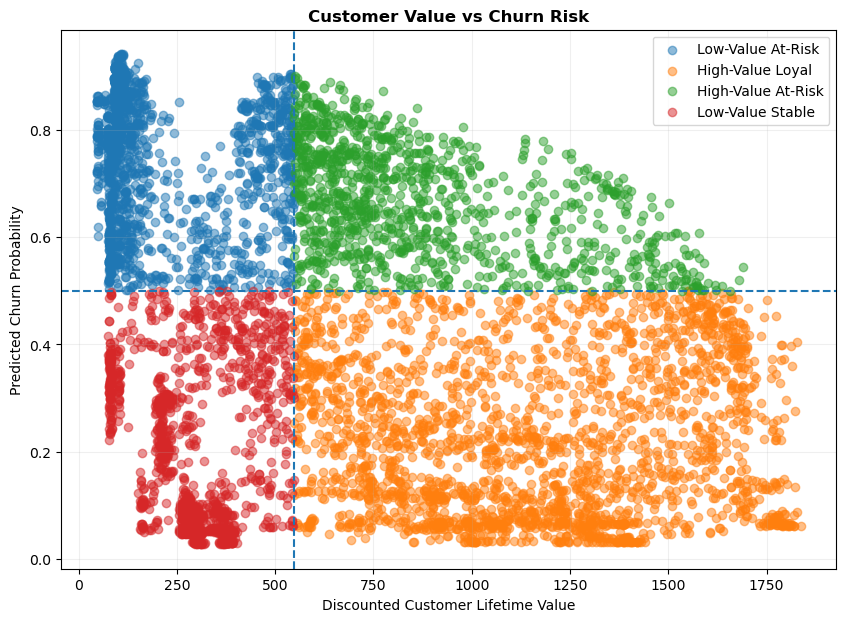

In [175]:
# ============================================================
# STEP 80: VISUALIZE CUSTOMER VALUE VS CHURN RISK
# Purpose:
# - Identify high-value, high-risk retention targets
# ============================================================

plt.figure(figsize=(10, 7))

for segment in df["BusinessSegment"].unique():

    subset = df[
        df["BusinessSegment"] == segment
    ]

    plt.scatter(
        subset["DiscountedCLV"],
        subset["ChurnProbability"],
        alpha=0.5,
        label=segment
    )

plt.axhline(
    high_risk_cutoff,
    linestyle="--"
)

plt.axvline(
    high_value_cutoff,
    linestyle="--"
)

plt.xlabel("Discounted Customer Lifetime Value")
plt.ylabel("Predicted Churn Probability")

plt.title(
    "Customer Value vs Churn Risk",
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [176]:
# ============================================================
# STEP 81: ASSIGN INITIAL RETENTION STRATEGY
# Purpose:
# - Convert model outputs into business actions
# ============================================================

strategy_map = {

    "High-Value At-Risk":
        "Priority retention intervention",

    "High-Value Loyal":
        "Protect relationship and consider loyalty rewards",

    "Low-Value At-Risk":
        "Use low-cost retention intervention",

    "Low-Value Stable":
        "No immediate retention action"
}

df["RetentionStrategy"] = (
    df["BusinessSegment"]
    .map(strategy_map)
)

display(
    df[
        [
            "customerID",
            "ChurnProbability",
            "DiscountedCLV",
            "BusinessSegment",
            "RetentionStrategy"
        ]
    ]
    .sort_values(
        [
            "BusinessSegment",
            "ChurnProbability"
        ],
        ascending=[
            True,
            False
        ]
    )
    .head(20)
)

,customerID,ChurnProbability,DiscountedCLV,BusinessSegment,RetentionStrategy
905,0781-LKXBR,0.90,550.06,High-Value At-Risk,Priority retention intervention
5874,2968-SSGAA,0.90,554.56,High-Value At-Risk,Priority retention intervention
4453,1455-UGQVH,0.90,549.54,High-Value At-Risk,Priority retention intervention
1073,0655-RBDUG,0.89,640.31,High-Value At-Risk,Priority retention intervention
4517,2012-NWRPA,0.89,563.04,High-Value At-Risk,Priority retention intervention
3587,6210-KBBPI,0.88,663.98,High-Value At-Risk,Priority retention intervention
5390,7450-NWRTR,0.88,574.06,High-Value At-Risk,Priority retention intervention
4826,3389-YGYAI,0.88,576.47,High-Value At-Risk,Priority retention intervention
6839,4078-SAYYN,0.88,567.57,High-Value At-Risk,Priority retention intervention
3349,0897-FEGMU,0.88,569.90,High-Value At-Risk,Priority retention intervention


In [177]:
# ============================================================
# STEP 82: INSTALL CAUSALML
# Purpose:
# - Perform uplift / treatment-effect modeling
# - Identify customers whose behavior changes because of an offer
# ============================================================

%pip install causalml -q

import pandas as pd
import numpy as np

print("✅ CausalML installed successfully")

Note: you may need to restart the kernel to use updated packages.
✅ CausalML installed successfully


  error: subprocess-exited-with-error
  
  × Building wheel for causalml (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [336 lines of output]
      C:\Users\lonka\AppData\Local\Temp\pip-build-env-q4ne1bbe\overlay\Lib\site-packages\setuptools\config\_apply_pyprojecttoml.py:61: SetuptoolsDeprecationWarning: License classifiers are deprecated.
      !!
      
              ********************************************************************************
              Please consider removing the following classifiers in favor of a SPDX license expression:
      
              License :: OSI Approved :: Apache Software License
      
              See https://packaging.python.org/en/latest/guides/writing-pyproject-toml/#license for details.
              ********************************************************************************
      
      !!
        dist._finalize_license_expression()
      C:\Users\lonka\AppData\Local\Temp\pip-build-env-q4ne1bbe\overlay\Lib\site-

In [178]:
# ============================================================
# STEP 83: DOWNLOAD CRITEO UPLIFT DATASET
# Purpose:
# - Use a real treatment/control dataset
# - Load only a sample so the notebook stays manageable
# ============================================================

import pandas as pd

url = (
    "https://huggingface.co/datasets/criteo/"
    "criteo-uplift/resolve/main/"
    "criteo-research-uplift-v2.1.csv.gz"
)

print("Downloading Criteo uplift dataset...")

# Read only first 200,000 rows for portfolio project
uplift_df = pd.read_csv(
    url,
    compression="gzip",
    nrows=200_000
)

# Save local sample
uplift_df.to_csv(
    "Criteo-Uplift-Sample.csv",
    index=False
)

print("✅ Dataset loaded successfully")
print("Rows:", uplift_df.shape[0])
print("Columns:", uplift_df.shape[1])

display(uplift_df.head())

✅ Dataset loaded successfully
Rows: 200000
Columns: 16


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.62,10.06,8.98,4.68,10.28,4.12,0.29,4.83,3.96,13.19,5.30,-0.17,1,0,0,0
1,12.62,10.06,9.00,4.68,10.28,4.12,0.29,4.83,3.96,13.19,5.30,-0.17,1,0,0,0
2,12.62,10.06,8.96,4.68,10.28,4.12,0.29,4.83,3.96,13.19,5.30,-0.17,1,0,0,0
3,12.62,10.06,9.00,4.68,10.28,4.12,0.29,4.83,3.96,13.19,5.30,-0.17,1,0,0,0
4,12.62,10.06,9.04,4.68,10.28,4.12,0.29,4.83,3.96,13.19,5.30,-0.17,1,0,0,0


In [179]:
# ============================================================
# STEP 83B: CREATE A BALANCED CRITEO UPLIFT SAMPLE
# Purpose:
# - Read the large Criteo dataset in chunks
# - Collect BOTH treatment and control customers
# - Build a manageable balanced sample for uplift modeling
# ============================================================

import pandas as pd
import numpy as np

url = (
    "https://huggingface.co/datasets/criteo/"
    "criteo-uplift/resolve/main/"
    "criteo-research-uplift-v2.1.csv.gz"
)

# ------------------------------------------------------------
# Sampling target
# ------------------------------------------------------------

TARGET_TREATED = 100_000
TARGET_CONTROL = 100_000

treated_parts = []
control_parts = []

treated_count = 0
control_count = 0

print("Building balanced uplift sample...")

# ------------------------------------------------------------
# Stream dataset instead of loading everything into memory
# ------------------------------------------------------------

reader = pd.read_csv(
    url,
    compression="gzip",
    chunksize=200_000
)

for chunk_number, chunk in enumerate(reader, start=1):

    # Separate treatment and control
    treated_chunk = chunk[
        chunk["treatment"] == 1
    ]

    control_chunk = chunk[
        chunk["treatment"] == 0
    ]

    # --------------------------------------------------------
    # Collect treated observations
    # --------------------------------------------------------

    if treated_count < TARGET_TREATED:

        remaining = (
            TARGET_TREATED - treated_count
        )

        if len(treated_chunk) > 0:

            sample_n = min(
                remaining,
                len(treated_chunk)
            )

            sample = treated_chunk.sample(
                n=sample_n,
                random_state=42 + chunk_number
            )

            treated_parts.append(sample)

            treated_count += sample_n

    # --------------------------------------------------------
    # Collect control observations
    # --------------------------------------------------------

    if control_count < TARGET_CONTROL:

        remaining = (
            TARGET_CONTROL - control_count
        )

        if len(control_chunk) > 0:

            sample_n = min(
                remaining,
                len(control_chunk)
            )

            sample = control_chunk.sample(
                n=sample_n,
                random_state=100 + chunk_number
            )

            control_parts.append(sample)

            control_count += sample_n

    print(
        f"Chunk {chunk_number:02d} | "
        f"Treated: {treated_count:,} | "
        f"Control: {control_count:,}"
    )

    # Stop once enough observations are collected
    if (
        treated_count >= TARGET_TREATED
        and
        control_count >= TARGET_CONTROL
    ):
        break


# ============================================================
# COMBINE TREATED + CONTROL SAMPLE
# ============================================================

if treated_count == 0 or control_count == 0:
    raise ValueError(
        "Could not obtain both treatment and control groups."
    )

uplift_df = pd.concat(
    treated_parts + control_parts,
    ignore_index=True
)

# Shuffle final dataset
uplift_df = uplift_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)


# ============================================================
# SAVE LOCAL COPY
# ============================================================

uplift_df.to_csv(
    "Criteo-Uplift-Balanced.csv",
    index=False
)


# ============================================================
# VALIDATION
# ============================================================

print("\n" + "=" * 60)
print("BALANCED CRITEO DATASET CREATED")
print("=" * 60)

print("Dataset Shape:")
print(uplift_df.shape)

print("\nTreatment Distribution:")
print(
    uplift_df["treatment"]
    .value_counts()
)

print("\nTreatment Percentage:")
print(
    uplift_df["treatment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nVisit Rate by Treatment:")
print(
    uplift_df.groupby(
        "treatment"
    )["visit"]
    .mean()
    .mul(100)
    .round(3)
)

display(uplift_df.head())

Building balanced uplift sample...
Chunk 01 | Treated: 100,000 | Control: 0
Chunk 02 | Treated: 100,000 | Control: 0
Chunk 03 | Treated: 100,000 | Control: 0
Chunk 04 | Treated: 100,000 | Control: 0
Chunk 05 | Treated: 100,000 | Control: 0
Chunk 06 | Treated: 100,000 | Control: 0
Chunk 07 | Treated: 100,000 | Control: 0
Chunk 08 | Treated: 100,000 | Control: 0
Chunk 09 | Treated: 100,000 | Control: 0
Chunk 10 | Treated: 100,000 | Control: 0
Chunk 11 | Treated: 100,000 | Control: 0
Chunk 12 | Treated: 100,000 | Control: 0
Chunk 13 | Treated: 100,000 | Control: 0
Chunk 14 | Treated: 100,000 | Control: 0
Chunk 15 | Treated: 100,000 | Control: 0
Chunk 16 | Treated: 100,000 | Control: 0
Chunk 17 | Treated: 100,000 | Control: 0
Chunk 18 | Treated: 100,000 | Control: 0
Chunk 19 | Treated: 100,000 | Control: 0
Chunk 20 | Treated: 100,000 | Control: 0
Chunk 21 | Treated: 100,000 | Control: 0
Chunk 22 | Treated: 100,000 | Control: 0
Chunk 23 | Treated: 100,000 | Control: 0
Chunk 24 | Treated: 10

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.62,10.06,8.99,4.68,10.28,4.12,0.29,4.83,3.94,13.19,5.30,-0.17,0,0,0,0
1,12.62,10.06,8.75,4.68,10.28,4.12,0.29,4.83,3.94,13.19,5.30,-0.17,1,0,0,0
2,23.99,10.06,8.89,4.68,10.28,4.12,-9.24,4.83,3.86,13.19,5.30,-0.17,0,0,0,0
3,25.87,10.06,8.21,4.68,10.28,4.12,-3.28,4.83,3.97,13.19,5.30,-0.17,1,0,0,0
4,12.62,10.06,8.87,4.68,10.28,4.12,0.29,4.83,3.96,13.19,5.30,-0.17,1,0,0,0


In [180]:
# ============================================================
# STEP 84: INSPECT CRITEO UPLIFT DATASET
# Purpose:
# - Verify treatment and outcomes
# ============================================================

print("Dataset Shape:")
print(uplift_df.shape)

print("\nColumns:")
print(uplift_df.columns.tolist())

print("\nTreatment Distribution:")
print(
    uplift_df["treatment"]
    .value_counts()
)

print("\nVisit Distribution:")
print(
    uplift_df["visit"]
    .value_counts()
)

print("\nConversion Distribution:")
print(
    uplift_df["conversion"]
    .value_counts()
)

display(uplift_df.head())

Dataset Shape:
(200000, 16)

Columns:
['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']

Treatment Distribution:
treatment
0    100000
1    100000
Name: count, dtype: int64

Visit Distribution:
visit
0    195327
1      4673
Name: count, dtype: int64

Conversion Distribution:
conversion
0    199209
1       791
Name: count, dtype: int64


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.62,10.06,8.99,4.68,10.28,4.12,0.29,4.83,3.94,13.19,5.30,-0.17,0,0,0,0
1,12.62,10.06,8.75,4.68,10.28,4.12,0.29,4.83,3.94,13.19,5.30,-0.17,1,0,0,0
2,23.99,10.06,8.89,4.68,10.28,4.12,-9.24,4.83,3.86,13.19,5.30,-0.17,0,0,0,0
3,25.87,10.06,8.21,4.68,10.28,4.12,-3.28,4.83,3.97,13.19,5.30,-0.17,1,0,0,0
4,12.62,10.06,8.87,4.68,10.28,4.12,0.29,4.83,3.96,13.19,5.30,-0.17,1,0,0,0


In [181]:
# ============================================================
# STEP 85: CALCULATE OBSERVED TREATMENT EFFECT
# Purpose:
# - Compare visit rate between treatment and control groups
# - Measure the average observed uplift before model training
# ============================================================

# ------------------------------------------------------------
# 1. Calculate control group visit rate
# ------------------------------------------------------------

control_rate = (
    uplift_df.loc[
        uplift_df["treatment"] == 0,
        "visit"
    ]
    .mean()
)


# ------------------------------------------------------------
# 2. Calculate treatment group visit rate
# ------------------------------------------------------------

treatment_rate = (
    uplift_df.loc[
        uplift_df["treatment"] == 1,
        "visit"
    ]
    .mean()
)


# ------------------------------------------------------------
# 3. Calculate absolute uplift
# ------------------------------------------------------------

absolute_uplift = (
    treatment_rate - control_rate
)


# ------------------------------------------------------------
# 4. Calculate relative uplift
# ------------------------------------------------------------

relative_uplift = (
    absolute_uplift / control_rate
)


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("=" * 65)
print("OBSERVED TREATMENT EFFECT")
print("=" * 65)

print(
    f"Control Visit Rate       : "
    f"{control_rate:.3%}"
)

print(
    f"Treatment Visit Rate     : "
    f"{treatment_rate:.3%}"
)

print(
    f"Absolute Uplift          : "
    f"{absolute_uplift:.3%}"
)

print(
    f"Relative Improvement     : "
    f"{relative_uplift:.2%}"
)

print("=" * 65)

OBSERVED TREATMENT EFFECT
Control Visit Rate       : 2.204%
Treatment Visit Rate     : 2.469%
Absolute Uplift          : 0.265%
Relative Improvement     : 12.02%


In [182]:
# ============================================================
# STEP 86: PREPARE FEATURES FOR UPLIFT MODELING
# Purpose:
# - Use only pre-treatment features f0-f11
# - Exclude treatment, exposure, visit, and conversion
# ============================================================

feature_cols = [
    "f0", "f1", "f2", "f3", "f4", "f5",
    "f6", "f7", "f8", "f9", "f10", "f11"
]

X_uplift = uplift_df[feature_cols].copy()

treatment_uplift = uplift_df[
    "treatment"
].astype(int)

y_uplift = uplift_df[
    "visit"
].astype(int)

print("=" * 60)
print("UPLIFT MODEL DATA")
print("=" * 60)

print("Feature matrix shape:", X_uplift.shape)

print("\nTreatment distribution:")
print(
    treatment_uplift.value_counts()
)

print("\nOutcome distribution:")
print(
    y_uplift.value_counts()
)

display(X_uplift.head())

UPLIFT MODEL DATA
Feature matrix shape: (200000, 12)

Treatment distribution:
treatment
0    100000
1    100000
Name: count, dtype: int64

Outcome distribution:
visit
0    195327
1      4673
Name: count, dtype: int64


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11
0,12.62,10.06,8.99,4.68,10.28,4.12,0.29,4.83,3.94,13.19,5.30,-0.17
1,12.62,10.06,8.75,4.68,10.28,4.12,0.29,4.83,3.94,13.19,5.30,-0.17
2,23.99,10.06,8.89,4.68,10.28,4.12,-9.24,4.83,3.86,13.19,5.30,-0.17
3,25.87,10.06,8.21,4.68,10.28,4.12,-3.28,4.83,3.97,13.19,5.30,-0.17
4,12.62,10.06,8.87,4.68,10.28,4.12,0.29,4.83,3.96,13.19,5.30,-0.17


In [183]:
# ============================================================
# STEP 87: TRAIN-TEST SPLIT FOR UPLIFT MODEL
# Purpose:
# - Keep a holdout test set
# - Preserve treatment/control balance
# ============================================================

from sklearn.model_selection import train_test_split

(
    X_u_train,
    X_u_test,
    t_u_train,
    t_u_test,
    y_u_train,
    y_u_test
) = train_test_split(
    X_uplift,
    treatment_uplift,
    y_uplift,
    test_size=0.25,
    random_state=42,
    stratify=treatment_uplift
)

print("Training rows:", X_u_train.shape[0])
print("Testing rows :", X_u_test.shape[0])

print("\nTraining treatment distribution:")
print(
    t_u_train.value_counts()
)

print("\nTesting treatment distribution:")
print(
    t_u_test.value_counts()
)

Training rows: 150000
Testing rows : 50000

Training treatment distribution:
treatment
1    75000
0    75000
Name: count, dtype: int64

Testing treatment distribution:
treatment
0    25000
1    25000
Name: count, dtype: int64


In [188]:
# ============================================================
# STEP 88: TRAIN MANUAL T-LEARNER UPLIFT MODEL
# Python 3.13 Compatible
#
# Purpose:
# - Avoid CausalML installation issue on Python 3.13
# - Train separate LightGBM models for:
#       1. Treatment group
#       2. Control group
# - Estimate Individual Treatment Effect (ITE / Uplift)
# ============================================================

import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier


# ------------------------------------------------------------
# 1. Separate treated and control training customers
# ------------------------------------------------------------

treated_mask = (
    t_u_train.values == 1
)

control_mask = (
    t_u_train.values == 0
)


X_train_treated = X_u_train.loc[
    treated_mask
]

y_train_treated = y_u_train.loc[
    treated_mask
]


X_train_control = X_u_train.loc[
    control_mask
]

y_train_control = y_u_train.loc[
    control_mask
]


print("=" * 65)
print("TRAINING GROUP SIZES")
print("=" * 65)

print(
    "Treatment customers:",
    len(X_train_treated)
)

print(
    "Control customers  :",
    len(X_train_control)
)


# ------------------------------------------------------------
# 2. Create treatment response model
# ------------------------------------------------------------

treatment_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=-1
)


# ------------------------------------------------------------
# 3. Create control response model
# ------------------------------------------------------------

control_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=-1
)


# ------------------------------------------------------------
# 4. Train treatment model
# ------------------------------------------------------------

treatment_model.fit(
    X_train_treated,
    y_train_treated
)


# ------------------------------------------------------------
# 5. Train control model
# ------------------------------------------------------------

control_model.fit(
    X_train_control,
    y_train_control
)


print("\n✅ Treatment model trained")
print("✅ Control model trained")


# ------------------------------------------------------------
# 6. Predict outcome if EVERY test customer were treated
# ------------------------------------------------------------

prob_if_treated = (
    treatment_model
    .predict_proba(X_u_test)[:, 1]
)


# ------------------------------------------------------------
# 7. Predict outcome if EVERY test customer were untreated
# ------------------------------------------------------------

prob_if_control = (
    control_model
    .predict_proba(X_u_test)[:, 1]
)


# ------------------------------------------------------------
# 8. Calculate Individual Treatment Effect / Uplift
#
# Uplift =
# P(visit | treatment)
# -
# P(visit | control)
# ------------------------------------------------------------

uplift_pred = (
    prob_if_treated
    -
    prob_if_control
)


# ------------------------------------------------------------
# 9. Create evaluation dataframe
# ------------------------------------------------------------

uplift_eval = pd.DataFrame({
    "treatment": t_u_test.values,
    "outcome": y_u_test.values,
    "prob_if_treated": prob_if_treated,
    "prob_if_control": prob_if_control,
    "uplift_score": uplift_pred
})


# ------------------------------------------------------------
# 10. Display results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("✅ MANUAL T-LEARNER TRAINED SUCCESSFULLY")
print("=" * 65)

print("\nPredicted uplift summary:")

display(
    uplift_eval["uplift_score"]
    .describe()
)


print("\nTop 10 customers by predicted uplift:")

display(
    uplift_eval
    .sort_values(
        "uplift_score",
        ascending=False
    )
    .head(10)
)

TRAINING GROUP SIZES
Treatment customers: 75000
Control customers  : 75000

✅ Treatment model trained
✅ Control model trained

✅ MANUAL T-LEARNER TRAINED SUCCESSFULLY

Predicted uplift summary:


count   50,000.00
mean         0.00
std          0.03
min         -0.53
25%         -0.00
50%          0.00
75%          0.00
max          0.63
Name: uplift_score, dtype: float64


Top 10 customers by predicted uplift:


,treatment,outcome,prob_if_treated,prob_if_control,uplift_score
37328,0,1,0.84,0.21,0.63
32965,0,0,0.75,0.15,0.60
22315,1,1,0.63,0.12,0.51
11172,0,1,0.68,0.17,0.50
34431,1,0,0.86,0.38,0.48
5275,1,1,0.53,0.06,0.47
11886,0,1,0.61,0.16,0.45
37142,1,0,0.55,0.10,0.45
40729,1,0,0.45,0.01,0.44
2643,1,0,0.74,0.31,0.43


In [189]:
# ============================================================
# STEP 89: CREATE UPLIFT DECILES
# Purpose:
# - Rank customers by predicted uplift
# - Divide them into 10 equal groups
# - Decile 1 = highest predicted uplift
# ============================================================

uplift_eval = uplift_eval.copy()

uplift_eval["uplift_decile"] = pd.qcut(
    uplift_eval["uplift_score"],
    q=10,
    labels=False,
    duplicates="drop"
)

# Reverse labels:
# 1 = highest uplift
# 10 = lowest uplift
uplift_eval["uplift_decile"] = (
    uplift_eval["uplift_decile"].max()
    - uplift_eval["uplift_decile"]
    + 1
)

print("=" * 60)
print("UPLIFT DECILE DISTRIBUTION")
print("=" * 60)

print(
    uplift_eval["uplift_decile"]
    .value_counts()
    .sort_index()
)

UPLIFT DECILE DISTRIBUTION
uplift_decile
1     5000
2     4999
3     4995
4     4999
5     4963
6     4690
7     5351
8     5003
9     5000
10    5000
Name: count, dtype: int64


In [190]:
# ============================================================
# STEP 90: OBSERVED UPLIFT BY DECILE
# Purpose:
# - Check whether top predicted-uplift customers
#   actually show higher treatment response
# ============================================================

decile_results = []

for decile in sorted(
    uplift_eval["uplift_decile"].unique()
):

    group = uplift_eval[
        uplift_eval["uplift_decile"] == decile
    ]

    treated_group = group[
        group["treatment"] == 1
    ]

    control_group = group[
        group["treatment"] == 0
    ]

    treatment_rate = (
        treated_group["outcome"].mean()
    )

    control_rate = (
        control_group["outcome"].mean()
    )

    observed_uplift = (
        treatment_rate - control_rate
    )

    decile_results.append({
        "Decile": int(decile),
        "Customers": len(group),
        "Treatment Visit Rate": treatment_rate,
        "Control Visit Rate": control_rate,
        "Observed Uplift": observed_uplift
    })


decile_df = pd.DataFrame(
    decile_results
)

display(
    decile_df.style.format({
        "Treatment Visit Rate": "{:.3%}",
        "Control Visit Rate": "{:.3%}",
        "Observed Uplift": "{:.3%}"
    })
)

,Decile,Customers,Treatment Visit Rate,Control Visit Rate,Observed Uplift
0,1,5000,13.084%,9.579%,3.505%
1,2,4999,1.563%,1.066%,0.498%
2,3,4995,0.159%,0.161%,-0.002%
3,4,4999,0.079%,0.000%,0.079%
4,5,4963,0.000%,0.040%,-0.040%
5,6,4690,0.042%,0.000%,0.042%
6,7,5351,0.000%,0.074%,-0.074%
7,8,5003,0.201%,0.119%,0.082%
8,9,5000,0.285%,0.275%,0.010%
9,10,5000,10.305%,10.136%,0.169%


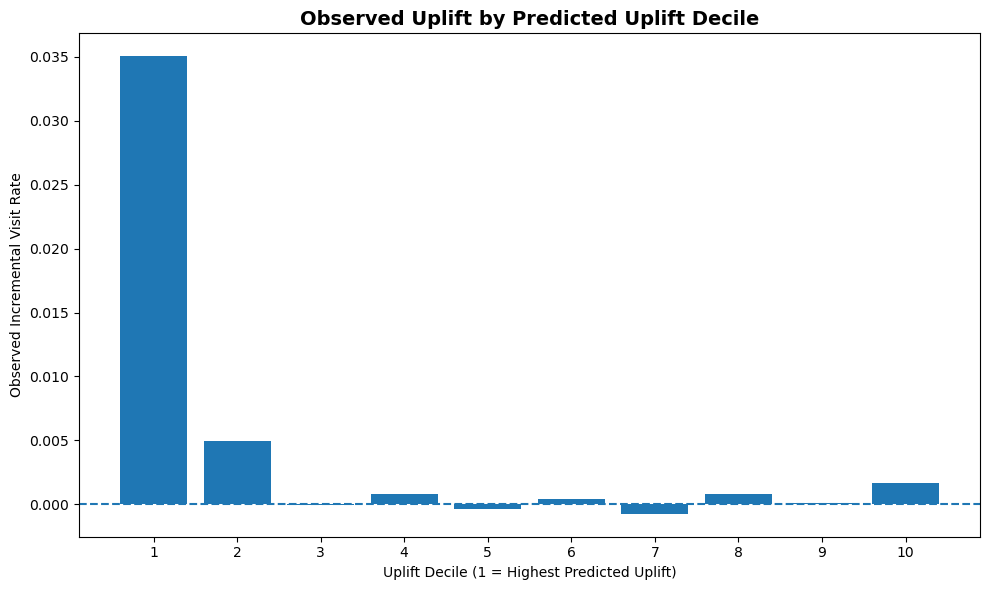

In [191]:
# ============================================================
# STEP 91: VISUALIZE OBSERVED UPLIFT BY DECILE
# Purpose:
# - Verify that highest-scored customers produce
#   the strongest actual treatment effect
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    decile_df["Decile"].astype(str),
    decile_df["Observed Uplift"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Observed Uplift by Predicted Uplift Decile",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Uplift Decile (1 = Highest Predicted Uplift)"
)

plt.ylabel(
    "Observed Incremental Visit Rate"
)

plt.tight_layout()
plt.show()

In [192]:
# ============================================================
# STEP 92: CALCULATE CUMULATIVE QINI CURVE
# Purpose:
# - Evaluate whether ranking customers by predicted uplift
#   generates incremental outcomes above random targeting
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Sort customers from highest to lowest predicted uplift
# ------------------------------------------------------------

qini_df = (
    uplift_eval
    .sort_values(
        "uplift_score",
        ascending=False
    )
    .reset_index(drop=True)
    .copy()
)


# ------------------------------------------------------------
# 2. Create treated/control outcome components
# ------------------------------------------------------------

qini_df["treated_customer"] = (
    qini_df["treatment"] == 1
).astype(int)

qini_df["control_customer"] = (
    qini_df["treatment"] == 0
).astype(int)

qini_df["treated_response"] = (
    qini_df["outcome"]
    * qini_df["treated_customer"]
)

qini_df["control_response"] = (
    qini_df["outcome"]
    * qini_df["control_customer"]
)


# ------------------------------------------------------------
# 3. Cumulative counts
# ------------------------------------------------------------

qini_df["cum_treated"] = (
    qini_df["treated_customer"].cumsum()
)

qini_df["cum_control"] = (
    qini_df["control_customer"].cumsum()
)

qini_df["cum_treated_response"] = (
    qini_df["treated_response"].cumsum()
)

qini_df["cum_control_response"] = (
    qini_df["control_response"].cumsum()
)


# ------------------------------------------------------------
# 4. Calculate cumulative incremental outcomes
#
# Qini =
# treated responses
# -
# expected treated responses under control behavior
# ------------------------------------------------------------

qini_df["qini_gain"] = np.where(
    qini_df["cum_control"] > 0,

    qini_df["cum_treated_response"]
    -
    (
        qini_df["cum_control_response"]
        *
        qini_df["cum_treated"]
        /
        qini_df["cum_control"]
    ),

    0
)


# ------------------------------------------------------------
# 5. Population targeted %
# ------------------------------------------------------------

qini_df["population_fraction"] = (
    np.arange(1, len(qini_df) + 1)
    / len(qini_df)
)


# ------------------------------------------------------------
# 6. Random targeting baseline
# ------------------------------------------------------------

final_gain = qini_df["qini_gain"].iloc[-1]

qini_df["random_gain"] = (
    qini_df["population_fraction"]
    * final_gain
)


print("✅ Qini curve calculated")
print(
    "Final incremental outcomes:",
    round(final_gain, 2)
)


✅ Qini curve calculated
Final incremental outcomes: 103.0


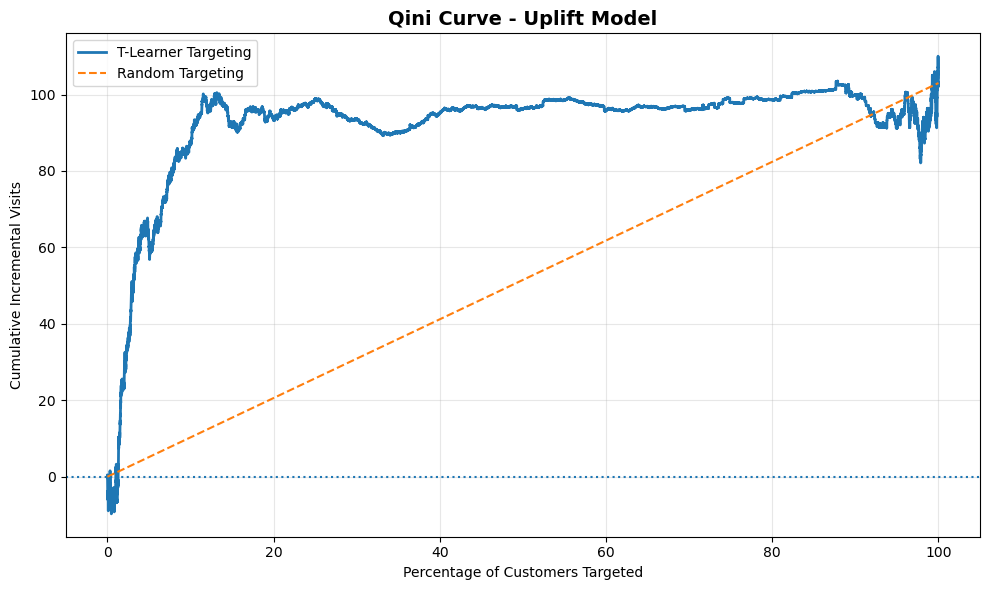

In [193]:
# ============================================================
# STEP 93: VISUALIZE QINI CURVE
# Purpose:
# - Compare model-based targeting with random targeting
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    qini_df["population_fraction"] * 100,
    qini_df["qini_gain"],
    label="T-Learner Targeting",
    linewidth=2
)

plt.plot(
    qini_df["population_fraction"] * 100,
    qini_df["random_gain"],
    linestyle="--",
    label="Random Targeting"
)

plt.axhline(
    0,
    linestyle=":"
)

plt.xlabel("Percentage of Customers Targeted")
plt.ylabel("Cumulative Incremental Visits")

plt.title(
    "Qini Curve - Uplift Model",
    fontsize=14,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [194]:
# ============================================================
# STEP 94: CALCULATE QINI COEFFICIENT
# Purpose:
# - Quantify improvement over random targeting
# ============================================================

x = qini_df[
    "population_fraction"
].values

model_curve = qini_df[
    "qini_gain"
].values

random_curve = qini_df[
    "random_gain"
].values


# Area under model Qini curve
model_area = np.trapezoid(
    model_curve,
    x
)

# Area under random baseline
random_area = np.trapezoid(
    random_curve,
    x
)

# Qini coefficient
qini_coefficient = (
    model_area - random_area
)

print("=" * 65)
print("QINI MODEL EVALUATION")
print("=" * 65)

print(
    f"Area Under Model Curve : "
    f"{model_area:.3f}"
)

print(
    f"Area Under Random Curve: "
    f"{random_area:.3f}"
)

print(
    f"Qini Coefficient       : "
    f"{qini_coefficient:.3f}"
)

if qini_coefficient > 0:
    print(
        "\n✅ Model ranks treatment-responsive "
        "customers better than random targeting."
    )
else:
    print(
        "\n⚠️ Model does not outperform random targeting."
    )

QINI MODEL EVALUATION
Area Under Model Curve : 92.119
Area Under Random Curve: 51.500
Qini Coefficient       : 40.619

✅ Model ranks treatment-responsive customers better than random targeting.


In [195]:
# ============================================================
# STEP 95: TARGETING PERFORMANCE BY POPULATION PERCENTAGE
# Purpose:
# - Evaluate campaign performance at different targeting sizes
# ============================================================

target_levels = [
    0.10,
    0.20,
    0.30,
    0.40,
    0.50
]

target_results = []

for fraction in target_levels:

    n = int(
        len(qini_df) * fraction
    )

    targeted = qini_df.iloc[:n]

    treated = targeted[
        targeted["treatment"] == 1
    ]

    control = targeted[
        targeted["treatment"] == 0
    ]

    treatment_rate = (
        treated["outcome"].mean()
    )

    control_rate = (
        control["outcome"].mean()
    )

    observed_uplift = (
        treatment_rate
        -
        control_rate
    )

    target_results.append({
        "Target Population": f"{int(fraction*100)}%",
        "Customers": n,
        "Treatment Rate": treatment_rate,
        "Control Rate": control_rate,
        "Observed Uplift": observed_uplift
    })


targeting_df = pd.DataFrame(
    target_results
)

display(
    targeting_df.style.format({
        "Treatment Rate": "{:.3%}",
        "Control Rate": "{:.3%}",
        "Observed Uplift": "{:.3%}"
    })
)

,Target Population,Customers,Treatment Rate,Control Rate,Observed Uplift
0,10%,5000,13.084%,9.579%,3.505%
1,20%,10000,7.236%,5.387%,1.849%
2,30%,15000,4.878%,3.644%,1.234%
3,40%,20000,3.678%,2.734%,0.945%
4,50%,25000,2.953%,2.187%,0.767%


In [196]:
# ============================================================
# STEP 96: DEFINE RETENTION ECONOMICS ASSUMPTIONS
# Purpose:
# - Convert churn risk, CLV and uplift into financial value
# - Prepare retention decision engine
# ============================================================

# Best observed uplift from Criteo top 10% segment
DEFAULT_UPLIFT_RATE = 0.03505

# Example retention offer
DEFAULT_DISCOUNT_RATE = 0.10

# Offer duration in months
OFFER_MONTHS = 3

# Estimated gross margin rate
MARGIN_RATE = 0.30

print("=" * 65)
print("RETENTION ECONOMICS ASSUMPTIONS")
print("=" * 65)

print(
    f"Expected Treatment Uplift : "
    f"{DEFAULT_UPLIFT_RATE:.3%}"
)

print(
    f"Retention Discount        : "
    f"{DEFAULT_DISCOUNT_RATE:.0%}"
)

print(
    f"Offer Duration            : "
    f"{OFFER_MONTHS} months"
)

print(
    f"Gross Margin Rate         : "
    f"{MARGIN_RATE:.0%}"
)

RETENTION ECONOMICS ASSUMPTIONS
Expected Treatment Uplift : 3.505%
Retention Discount        : 10%
Offer Duration            : 3 months
Gross Margin Rate         : 30%


In [197]:
# ============================================================
# STEP 97: CALCULATE CUSTOMER-SPECIFIC OFFER COST
# Purpose:
# - Estimate cost of offering a temporary discount
# ============================================================

df["OfferCost"] = (
    df["MonthlyCharges"]
    * DEFAULT_DISCOUNT_RATE
    * OFFER_MONTHS
)

display(
    df[
        [
            "customerID",
            "MonthlyCharges",
            "OfferCost"
        ]
    ].head()
)

,customerID,MonthlyCharges,OfferCost
0,7590-VHVEG,29.85,8.96
1,5575-GNVDE,56.95,17.09
2,3668-QPYBK,53.85,16.16
3,7795-CFOCW,42.30,12.69
4,9237-HQITU,70.70,21.21


In [198]:
# ============================================================
# STEP 98: CALCULATE EXPECTED RETENTION BENEFIT
# Purpose:
# - Estimate incremental economic value from intervention
#
# Logic:
# ExpectedBenefit =
# ChurnProbability
# × TreatmentUplift
# × CustomerLifetimeValue
# ============================================================

df["ExpectedRetentionBenefit"] = (
    df["ChurnProbability"]
    * DEFAULT_UPLIFT_RATE
    * df["DiscountedCLV"]
)

display(
    df[
        [
            "customerID",
            "ChurnProbability",
            "DiscountedCLV",
            "ExpectedRetentionBenefit"
        ]
    ].head()
)

,customerID,ChurnProbability,DiscountedCLV,ExpectedRetentionBenefit
0,7590-VHVEG,0.80,57.78,1.61
1,5575-GNVDE,0.12,737.16,3.02
2,3668-QPYBK,0.61,132.22,2.83
3,7795-CFOCW,0.13,609.20,2.71
4,9237-HQITU,0.82,91.25,2.63


In [199]:
# ============================================================
# STEP 99: CALCULATE NET BENEFIT AND ROI
# Purpose:
# - Compare expected retained value against offer cost
# ============================================================

df["NetRetentionBenefit"] = (
    df["ExpectedRetentionBenefit"]
    -
    df["OfferCost"]
)

df["RetentionROI"] = np.where(
    df["OfferCost"] > 0,

    df["NetRetentionBenefit"]
    /
    df["OfferCost"],

    0
)

display(
    df[
        [
            "customerID",
            "OfferCost",
            "ExpectedRetentionBenefit",
            "NetRetentionBenefit",
            "RetentionROI"
        ]
    ]
    .sort_values(
        "RetentionROI",
        ascending=False
    )
    .head(20)
)

,customerID,OfferCost,ExpectedRetentionBenefit,NetRetentionBenefit,RetentionROI
2860,2452-KDRRH,30.42,33.73,3.31,0.11
4074,0946-CLJTI,29.61,32.82,3.21,0.11
2850,2277-DJJDL,29.70,32.76,3.06,0.10
6745,5515-AKOAJ,30.03,33.11,3.08,0.10
2282,1587-FKLZB,29.85,32.84,2.99,0.10
3330,8276-MQBYC,29.34,32.27,2.93,0.10
402,0979-PHULV,29.84,32.76,2.93,0.10
2075,7901-TBKJX,30.32,33.25,2.94,0.10
1339,3838-OZURD,31.50,34.47,2.97,0.09
4083,0324-BRPCJ,30.06,32.76,2.70,0.09


In [200]:
# ============================================================
# STEP 100: RETENTION DECISION ENGINE
# Purpose:
# - Turn model outputs into actionable decisions
# ============================================================

def retention_decision(row):

    # High risk + profitable intervention
    if (
        row["ChurnProbability"] >= 0.50
        and
        row["NetRetentionBenefit"] > 0
    ):
        return "SEND OFFER"

    # High risk but economically unattractive
    elif (
        row["ChurnProbability"] >= 0.50
        and
        row["NetRetentionBenefit"] <= 0
    ):
        return "DO NOT DISCOUNT"

    # Valuable but currently stable
    elif (
        row["ChurnProbability"] < 0.50
        and
        row["DiscountedCLV"]
        >= df["DiscountedCLV"].median()
    ):
        return "PROTECT / LOYALTY"

    else:
        return "NO ACTION"


df["RecommendedAction"] = df.apply(
    retention_decision,
    axis=1
)

print("Retention recommendations:")

display(
    df["RecommendedAction"]
    .value_counts()
    .to_frame("Customers")
)

Retention recommendations:


,Customers
RecommendedAction,
DO NOT DISCOUNT,2810
PROTECT / LOYALTY,2389
NO ACTION,1788
SEND OFFER,56


In [201]:
# ============================================================
# STEP 101: FINAL CUSTOMER RETENTION INTELLIGENCE TABLE
# Purpose:
# - Combine all major model outputs into one business view
# ============================================================

final_customer_table = df[
    [
        "customerID",
        "ChurnProbability",
        "ExpectedLifetimeMonths",
        "DiscountedCLV",
        "BusinessSegment",
        "OfferCost",
        "ExpectedRetentionBenefit",
        "NetRetentionBenefit",
        "RetentionROI",
        "RecommendedAction"
    ]
].copy()

final_customer_table = (
    final_customer_table
    .sort_values(
        [
            "RecommendedAction",
            "NetRetentionBenefit"
        ],
        ascending=[
            True,
            False
        ]
    )
)

display(
    final_customer_table.head(30).style.format({
        "ChurnProbability": "{:.2%}",
        "ExpectedLifetimeMonths": "{:.1f}",
        "DiscountedCLV": "${:,.2f}",
        "OfferCost": "${:,.2f}",
        "ExpectedRetentionBenefit": "${:,.2f}",
        "NetRetentionBenefit": "${:,.2f}",
        "RetentionROI": "{:.2%}"
    })
)

,customerID,ChurnProbability,ExpectedLifetimeMonths,DiscountedCLV,BusinessSegment,OfferCost,ExpectedRetentionBenefit,NetRetentionBenefit,RetentionROI,RecommendedAction
635,7207-RMRDB,64.96%,58.3,"$1,389.65",High-Value At-Risk,$31.65,$31.64,$-0.01,-0.03%,DO NOT DISCOUNT
2997,1891-FZYSA,66.26%,56.8,"$1,159.90",High-Value At-Risk,$26.99,$26.94,$-0.05,-0.18%,DO NOT DISCOUNT
6448,3685-YLCMQ,57.02%,68.2,"$1,566.62",High-Value At-Risk,$31.40,$31.31,$-0.08,-0.27%,DO NOT DISCOUNT
1749,1320-REHCS,64.00%,59.2,"$1,476.88",High-Value At-Risk,$33.23,$33.13,$-0.10,-0.29%,DO NOT DISCOUNT
1068,5536-RTPWK,66.48%,56.4,"$1,270.03",High-Value At-Risk,$29.72,$29.59,$-0.12,-0.41%,DO NOT DISCOUNT
4337,2674-MLXMN,61.46%,62.0,"$1,379.91",High-Value At-Risk,$29.90,$29.72,$-0.17,-0.57%,DO NOT DISCOUNT
2471,1323-OOEPC,65.27%,57.5,"$1,281.12",High-Value At-Risk,$29.52,$29.31,$-0.21,-0.71%,DO NOT DISCOUNT
4199,4088-YLDSU,56.72%,67.8,"$1,551.77",High-Value At-Risk,$31.25,$30.85,$-0.39,-1.26%,DO NOT DISCOUNT
513,8677-HDZEE,60.43%,62.8,"$1,474.96",High-Value At-Risk,$31.64,$31.24,$-0.40,-1.25%,DO NOT DISCOUNT
2277,3571-RFHAR,60.74%,62.3,"$1,517.03",High-Value At-Risk,$32.75,$32.30,$-0.45,-1.37%,DO NOT DISCOUNT


In [202]:
# ============================================================
# STEP 102: CREATE ROI SIMULATOR FUNCTION
# Purpose:
# - Simulate different discount rates
# - Estimate campaign cost
# - Estimate retained value
# - Calculate net benefit and ROI
# ============================================================

def simulate_retention_roi(
    data,
    discount_rate=0.10,
    offer_months=3,
    uplift_rate=0.03505,
    churn_threshold=0.50,
    target_top_percent=None
):

    sim = data.copy()

    # --------------------------------------------------------
    # 1. Optional targeting by top churn-risk customers
    # --------------------------------------------------------

    if target_top_percent is not None:

        cutoff = sim["ChurnProbability"].quantile(
            1 - target_top_percent
        )

        sim = sim[
            sim["ChurnProbability"] >= cutoff
        ].copy()

    else:

        sim = sim[
            sim["ChurnProbability"] >= churn_threshold
        ].copy()


    # --------------------------------------------------------
    # 2. Campaign offer cost
    # --------------------------------------------------------

    sim["SimOfferCost"] = (
        sim["MonthlyCharges"]
        * discount_rate
        * offer_months
    )


    # --------------------------------------------------------
    # 3. Expected incremental retained value
    # --------------------------------------------------------

    sim["SimExpectedBenefit"] = (
        sim["ChurnProbability"]
        * uplift_rate
        * sim["DiscountedCLV"]
    )


    # --------------------------------------------------------
    # 4. Net customer-level benefit
    # --------------------------------------------------------

    sim["SimNetBenefit"] = (
        sim["SimExpectedBenefit"]
        -
        sim["SimOfferCost"]
    )


    # --------------------------------------------------------
    # 5. Campaign totals
    # --------------------------------------------------------

    customers_targeted = len(sim)

    total_cost = sim["SimOfferCost"].sum()

    expected_value = sim[
        "SimExpectedBenefit"
    ].sum()

    net_benefit = (
        expected_value - total_cost
    )

    roi = (
        net_benefit / total_cost
        if total_cost > 0
        else 0
    )


    return {
        "Customers Targeted": customers_targeted,
        "Campaign Cost": total_cost,
        "Expected Retained Value": expected_value,
        "Net Benefit": net_benefit,
        "ROI": roi
    }

In [203]:
# ============================================================
# STEP 103: RUN BASELINE ROI SIMULATION
# ============================================================

baseline_roi = simulate_retention_roi(
    data=df,
    discount_rate=0.10,
    offer_months=3,
    uplift_rate=0.03505,
    churn_threshold=0.50
)

baseline_roi_df = pd.DataFrame(
    [baseline_roi]
)

display(
    baseline_roi_df.style.format({
        "Campaign Cost": "${:,.2f}",
        "Expected Retained Value": "${:,.2f}",
        "Net Benefit": "${:,.2f}",
        "ROI": "{:.2%}"
    })
)

,Customers Targeted,Campaign Cost,Expected Retained Value,Net Benefit,ROI
0,2866,"$63,980.51","$31,486.58","$-32,493.92",-50.79%


In [204]:
# ============================================================
# STEP 104: COMPARE MULTIPLE DISCOUNT SCENARIOS
# ============================================================

discount_scenarios = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25
]

scenario_results = []

for discount in discount_scenarios:

    result = simulate_retention_roi(
        data=df,
        discount_rate=discount,
        offer_months=3,
        uplift_rate=0.03505,
        churn_threshold=0.50
    )

    result[
        "Discount Rate"
    ] = discount

    scenario_results.append(
        result
    )

roi_scenarios_df = pd.DataFrame(
    scenario_results
)

roi_scenarios_df = roi_scenarios_df[
    [
        "Discount Rate",
        "Customers Targeted",
        "Campaign Cost",
        "Expected Retained Value",
        "Net Benefit",
        "ROI"
    ]
]

display(
    roi_scenarios_df.style.format({
        "Discount Rate": "{:.0%}",
        "Campaign Cost": "${:,.2f}",
        "Expected Retained Value": "${:,.2f}",
        "Net Benefit": "${:,.2f}",
        "ROI": "{:.2%}"
    })
)

,Discount Rate,Customers Targeted,Campaign Cost,Expected Retained Value,Net Benefit,ROI
0,5%,2866,"$31,990.25","$31,486.58",$-503.67,-1.57%
1,10%,2866,"$63,980.51","$31,486.58","$-32,493.92",-50.79%
2,15%,2866,"$95,970.76","$31,486.58","$-64,484.17",-67.19%
3,20%,2866,"$127,961.01","$31,486.58","$-96,474.43",-75.39%
4,25%,2866,"$159,951.26","$31,486.58","$-128,464.68",-80.31%


In [205]:
# ============================================================
# STEP 105: COMPARE TARGETING STRATEGIES
# Purpose:
# - Find whether targeting fewer high-risk customers
#   improves campaign ROI
# ============================================================

target_levels = [
    0.10,
    0.20,
    0.30,
    0.40,
    0.50
]

targeting_roi_results = []

for target_pct in target_levels:

    result = simulate_retention_roi(
        data=df,
        discount_rate=0.10,
        offer_months=3,
        uplift_rate=0.03505,
        target_top_percent=target_pct
    )

    result[
        "Target Population"
    ] = target_pct

    targeting_roi_results.append(
        result
    )

targeting_roi_df = pd.DataFrame(
    targeting_roi_results
)

targeting_roi_df = targeting_roi_df[
    [
        "Target Population",
        "Customers Targeted",
        "Campaign Cost",
        "Expected Retained Value",
        "Net Benefit",
        "ROI"
    ]
]

display(
    targeting_roi_df.style.format({
        "Target Population": "{:.0%}",
        "Campaign Cost": "${:,.2f}",
        "Expected Retained Value": "${:,.2f}",
        "Net Benefit": "${:,.2f}",
        "ROI": "{:.2%}"
    })
)

,Target Population,Customers Targeted,Campaign Cost,Expected Retained Value,Net Benefit,ROI
0,10%,709,"$17,289.19","$4,798.19","$-12,491.00",-72.25%
1,20%,1409,"$33,208.01","$12,771.11","$-20,436.89",-61.54%
2,30%,2113,"$49,036.20","$22,256.70","$-26,779.50",-54.61%
3,40%,2817,"$62,781.51","$30,666.23","$-32,115.28",-51.15%
4,50%,3522,"$78,968.24","$40,857.97","$-38,110.26",-48.26%


In [206]:
# ============================================================
# STEP 106: ADVANCED RETENTION ROI SIMULATOR
# Purpose:
# - Use causal retention uplift as a configurable assumption
# - Avoid treating Criteo visit uplift as telecom retention uplift
# - Calculate break-even economics
# - Support Streamlit sliders later
#
# IMPORTANT:
# Criteo validates the uplift MODELING APPROACH.
# retention_uplift below is a business scenario assumption.
# ============================================================

def advanced_retention_roi(
    data,
    discount_rate=0.05,
    offer_months=3,
    retention_uplift=0.05,
    target_top_percent=0.10
):

    sim = data.copy()

    # --------------------------------------------------------
    # 1. TARGET HIGHEST-RISK CUSTOMERS
    # --------------------------------------------------------

    churn_cutoff = sim["ChurnProbability"].quantile(
        1 - target_top_percent
    )

    sim = sim[
        sim["ChurnProbability"] >= churn_cutoff
    ].copy()


    # --------------------------------------------------------
    # 2. OFFER COST
    # --------------------------------------------------------

    sim["CampaignCost"] = (
        sim["MonthlyCharges"]
        * discount_rate
        * offer_months
    )


    # --------------------------------------------------------
    # 3. EXPECTED INCREMENTAL RETAINED VALUE
    #
    # retention_uplift =
    # causal increase in probability of retention
    #
    # Example:
    # 5% uplift means treatment increases probability
    # of retention by 5 percentage points.
    # --------------------------------------------------------

    sim["IncrementalRetainedValue"] = (
        retention_uplift
        * sim["DiscountedCLV"]
    )


    # --------------------------------------------------------
    # 4. CUSTOMER-LEVEL NET VALUE
    # --------------------------------------------------------

    sim["NetValue"] = (
        sim["IncrementalRetainedValue"]
        -
        sim["CampaignCost"]
    )


    # --------------------------------------------------------
    # 5. TOTAL CAMPAIGN ECONOMICS
    # --------------------------------------------------------

    customers_targeted = len(sim)

    total_cost = sim[
        "CampaignCost"
    ].sum()

    expected_retained_value = sim[
        "IncrementalRetainedValue"
    ].sum()

    net_benefit = (
        expected_retained_value
        -
        total_cost
    )

    roi = (
        net_benefit / total_cost
        if total_cost > 0
        else 0
    )


    # --------------------------------------------------------
    # 6. BREAK-EVEN UPLIFT
    # --------------------------------------------------------

    total_clv = sim[
        "DiscountedCLV"
    ].sum()

    break_even_uplift = (
        total_cost / total_clv
        if total_clv > 0
        else np.nan
    )


    return {
        "Target Population": target_top_percent,
        "Customers Targeted": customers_targeted,
        "Discount Rate": discount_rate,
        "Retention Uplift Assumption": retention_uplift,
        "Campaign Cost": total_cost,
        "Expected Retained Value": expected_retained_value,
        "Net Benefit": net_benefit,
        "ROI": roi,
        "Break-Even Uplift": break_even_uplift
    }


print("✅ Advanced ROI simulator created")

✅ Advanced ROI simulator created


In [207]:
# ============================================================
# STEP 107: BREAK-EVEN RETENTION UPLIFT ANALYSIS
# Purpose:
# - Determine minimum treatment effect required
#   for each discount level to be profitable
# ============================================================

discount_rates = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25
]

break_even_results = []

for discount in discount_rates:

    result = advanced_retention_roi(
        data=df,
        discount_rate=discount,
        offer_months=3,
        retention_uplift=0.05,
        target_top_percent=0.10
    )

    break_even_results.append(
        result
    )


break_even_df = pd.DataFrame(
    break_even_results
)

display(
    break_even_df[
        [
            "Discount Rate",
            "Customers Targeted",
            "Campaign Cost",
            "Break-Even Uplift"
        ]
    ].style.format({
        "Discount Rate": "{:.0%}",
        "Campaign Cost": "${:,.2f}",
        "Break-Even Uplift": "{:.2%}"
    })
)

,Discount Rate,Customers Targeted,Campaign Cost,Break-Even Uplift
0,5%,709,"$8,644.60",5.42%
1,10%,709,"$17,289.19",10.84%
2,15%,709,"$25,933.79",16.26%
3,20%,709,"$34,578.39",21.68%
4,25%,709,"$43,222.99",27.09%


In [208]:
# ============================================================
# STEP 108: ROI SENSITIVITY ANALYSIS
# Purpose:
# - Test several offer discounts
# - Test several causal retention uplift assumptions
# - Determine profitable campaign combinations
# ============================================================

discount_rates = [
    0.05,
    0.10,
    0.15,
    0.20
]

uplift_assumptions = [
    0.02,
    0.05,
    0.10,
    0.15,
    0.20
]

sensitivity_results = []

for discount in discount_rates:

    for uplift in uplift_assumptions:

        result = advanced_retention_roi(
            data=df,
            discount_rate=discount,
            offer_months=3,
            retention_uplift=uplift,
            target_top_percent=0.10
        )

        sensitivity_results.append({
            "Discount": discount,
            "Retention Uplift": uplift,
            "Customers Targeted":
                result["Customers Targeted"],
            "Campaign Cost":
                result["Campaign Cost"],
            "Expected Value":
                result["Expected Retained Value"],
            "Net Benefit":
                result["Net Benefit"],
            "ROI":
                result["ROI"]
        })


roi_sensitivity_df = pd.DataFrame(
    sensitivity_results
)

display(
    roi_sensitivity_df.style.format({
        "Discount": "{:.0%}",
        "Retention Uplift": "{:.0%}",
        "Campaign Cost": "${:,.2f}",
        "Expected Value": "${:,.2f}",
        "Net Benefit": "${:,.2f}",
        "ROI": "{:.1%}"
    })
)

,Discount,Retention Uplift,Customers Targeted,Campaign Cost,Expected Value,Net Benefit,ROI
0,5%,2%,709,"$8,644.60","$3,190.52","$-5,454.07",-63.1%
1,5%,5%,709,"$8,644.60","$7,976.31",$-668.29,-7.7%
2,5%,10%,709,"$8,644.60","$15,952.62","$7,308.02",84.5%
3,5%,15%,709,"$8,644.60","$23,928.93","$15,284.33",176.8%
4,5%,20%,709,"$8,644.60","$31,905.23","$23,260.64",269.1%
5,10%,2%,709,"$17,289.19","$3,190.52","$-14,098.67",-81.5%
6,10%,5%,709,"$17,289.19","$7,976.31","$-9,312.89",-53.9%
7,10%,10%,709,"$17,289.19","$15,952.62","$-1,336.58",-7.7%
8,10%,15%,709,"$17,289.19","$23,928.93","$6,639.73",38.4%
9,10%,20%,709,"$17,289.19","$31,905.23","$14,616.04",84.5%


In [209]:
# ============================================================
# STEP 109: IDENTIFY PROFITABLE RETENTION STRATEGIES
# Purpose:
# - Automatically identify campaign scenarios
#   that produce positive economic returns
# ============================================================

profitable_strategies = (
    roi_sensitivity_df[
        roi_sensitivity_df["Net Benefit"] > 0
    ]
    .sort_values(
        "ROI",
        ascending=False
    )
)

print("=" * 70)
print("PROFITABLE RETENTION STRATEGIES")
print("=" * 70)

if len(profitable_strategies) > 0:

    display(
        profitable_strategies.style.format({
            "Discount": "{:.0%}",
            "Retention Uplift": "{:.0%}",
            "Campaign Cost": "${:,.2f}",
            "Expected Value": "${:,.2f}",
            "Net Benefit": "${:,.2f}",
            "ROI": "{:.1%}"
        })
    )

else:

    print(
        "No tested scenario generated positive ROI."
    )

PROFITABLE RETENTION STRATEGIES


,Discount,Retention Uplift,Customers Targeted,Campaign Cost,Expected Value,Net Benefit,ROI
4,5%,20%,709,"$8,644.60","$31,905.23","$23,260.64",269.1%
3,5%,15%,709,"$8,644.60","$23,928.93","$15,284.33",176.8%
2,5%,10%,709,"$8,644.60","$15,952.62","$7,308.02",84.5%
9,10%,20%,709,"$17,289.19","$31,905.23","$14,616.04",84.5%
8,10%,15%,709,"$17,289.19","$23,928.93","$6,639.73",38.4%
14,15%,20%,709,"$25,933.79","$31,905.23","$5,971.44",23.0%


In [210]:
# ============================================================
# STEP 110: CREATE FINAL CUSTOMER INTELLIGENCE DATASET
# Purpose:
# - Create one clean table for the Streamlit application
# - Combine churn, survival, CLV, segmentation and ROI outputs
# ============================================================

final_columns = [
    "customerID",
    "gender",
    "SeniorCitizen",
    "tenure",
    "Contract",
    "InternetService",
    "TechSupport",
    "PaymentMethod",
    "MonthlyCharges",
    "TotalCharges",
    "ChurnFlag",
    "ChurnProbability",
    "ExpectedLifetimeMonths",
    "DiscountedCLV",
    "CLVSegment",
    "BusinessSegment",
    "RetentionStrategy"
]

final_columns = [
    col for col in final_columns
    if col in df.columns
]

customer_intelligence = df[
    final_columns
].copy()

customer_intelligence = (
    customer_intelligence
    .sort_values(
        "ChurnProbability",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "Final dataset shape:",
    customer_intelligence.shape
)

display(
    customer_intelligence.head(10)
)

Final dataset shape: (7043, 17)


,customerID,gender,SeniorCitizen,tenure,Contract,InternetService,TechSupport,PaymentMethod,MonthlyCharges,TotalCharges,ChurnFlag,ChurnProbability,ExpectedLifetimeMonths,DiscountedCLV,CLVSegment,BusinessSegment,RetentionStrategy
0,7216-EWTRS,Female,1,1,Month-to-month,Fiber optic,No,Electronic check,100.80,100.80,1,0.94,3.35,113.30,Low Value,Low-Value At-Risk,Use low-cost retention intervention
1,9300-AGZNL,Male,1,1,Month-to-month,Fiber optic,No,Electronic check,94.00,94.00,1,0.94,3.42,107.46,Low Value,Low-Value At-Risk,Use low-cost retention intervention
2,9497-QCMMS,Male,1,1,Month-to-month,Fiber optic,No,Electronic check,93.55,93.55,1,0.94,3.44,107.42,Low Value,Low-Value At-Risk,Use low-cost retention intervention
3,5178-LMXOP,Male,1,1,Month-to-month,Fiber optic,No,Electronic check,95.10,95.10,1,0.94,3.38,107.54,Low Value,Low-Value At-Risk,Use low-cost retention intervention
4,5419-JPRRN,Male,0,1,Month-to-month,Fiber optic,No,Electronic check,101.45,101.45,1,0.94,3.33,113.29,Low Value,Low-Value At-Risk,Use low-cost retention intervention
5,0295-PPHDO,Male,0,1,Month-to-month,Fiber optic,No,Electronic check,95.45,95.45,1,0.94,3.36,107.56,Low Value,Low-Value At-Risk,Use low-cost retention intervention
6,0107-YHINA,Male,0,1,Month-to-month,Fiber optic,No,Electronic check,99.75,99.75,1,0.94,3.39,113.29,Low Value,Low-Value At-Risk,Use low-cost retention intervention
7,1069-XAIEM,Female,1,1,Month-to-month,Fiber optic,No,Electronic check,85.05,85.05,1,0.94,3.58,101.02,Low Value,Low-Value At-Risk,Use low-cost retention intervention
8,8149-RSOUN,Female,0,1,Month-to-month,Fiber optic,No,Electronic check,93.85,93.85,1,0.94,3.43,107.45,Low Value,Low-Value At-Risk,Use low-cost retention intervention
9,4910-GMJOT,Female,0,1,Month-to-month,Fiber optic,No,Electronic check,94.60,94.60,1,0.94,3.40,107.50,Low Value,Low-Value At-Risk,Use low-cost retention intervention


In [211]:
# ============================================================
# STEP 111: SAVE FINAL CUSTOMER INTELLIGENCE DATASET
# ============================================================

customer_intelligence.to_csv(
    "customer_intelligence_final.csv",
    index=False
)

print(
    "✅ customer_intelligence_final.csv saved"
)

✅ customer_intelligence_final.csv saved


In [212]:
# ============================================================
# STEP 112: SAVE TRAINED MODEL + PREPROCESSOR
# Purpose:
# - Reuse model inside Streamlit without retraining
# ============================================================

import joblib

joblib.dump(
    optimized_lgb,
    "optimized_lightgbm_churn.pkl"
)

joblib.dump(
    preprocessor,
    "churn_preprocessor.pkl"
)

print("✅ Churn model saved")
print("✅ Preprocessor saved")

✅ Churn model saved
✅ Preprocessor saved


In [213]:
# ============================================================
# STEP 113: INSTALL STREAMLIT DASHBOARD DEPENDENCIES
# ============================================================

import sys
import subprocess

packages = [
    "streamlit",
    "plotly"
]

subprocess.check_call(
    [sys.executable, "-m", "pip", "install", "-q"] + packages
)

print("✅ Streamlit installed")
print("✅ Plotly installed")

✅ Streamlit installed
✅ Plotly installed


In [214]:
# ============================================================
# STEP 114: CREATE STREAMLIT APPLICATION
# Purpose:
# - Executive dashboard
# - Customer explorer
# - Churn intelligence
# - CLV analysis
# - Retention targeting
# - ROI simulator
# ============================================================

app_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px

# ------------------------------------------------------------
# PAGE CONFIGURATION
# ------------------------------------------------------------

st.set_page_config(
    page_title="Customer Lifetime Value & Churn Intelligence",
    page_icon="📊",
    layout="wide"
)

# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------

@st.cache_data
def load_data():
    return pd.read_csv("customer_intelligence_final.csv")


df = load_data()


# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

st.title("📊 Customer Lifetime Value & Churn Intelligence System")

st.caption(
    "AI-powered churn prediction, customer lifetime value, "
    "retention targeting and campaign ROI optimization."
)


# ------------------------------------------------------------
# SIDEBAR
# ------------------------------------------------------------

st.sidebar.header("Dashboard Filters")

risk_threshold = st.sidebar.slider(
    "High-Risk Churn Threshold",
    min_value=0.10,
    max_value=0.90,
    value=0.50,
    step=0.05
)

high_risk_df = df[
    df["ChurnProbability"] >= risk_threshold
].copy()


# ------------------------------------------------------------
# TABS
# ------------------------------------------------------------

tabs = st.tabs([
    "🏠 Executive Dashboard",
    "👤 Customer Explorer",
    "⚠️ Churn Intelligence",
    "💰 Survival & CLV",
    "🎯 Retention Targeting",
    "📈 ROI Simulator"
])


# ============================================================
# TAB 1: EXECUTIVE DASHBOARD
# ============================================================

with tabs[0]:

    st.header("Executive Customer Intelligence")

    total_customers = len(df)

    avg_churn_risk = df[
        "ChurnProbability"
    ].mean()

    high_risk_count = len(
        high_risk_df
    )

    total_clv = df[
        "DiscountedCLV"
    ].sum()

    col1, col2, col3, col4 = st.columns(4)

    col1.metric(
        "Customers",
        f"{total_customers:,}"
    )

    col2.metric(
        "Average Churn Risk",
        f"{avg_churn_risk:.1%}"
    )

    col3.metric(
        "High-Risk Customers",
        f"{high_risk_count:,}"
    )

    col4.metric(
        "Portfolio CLV",
        f"${total_clv:,.0f}"
    )


    st.subheader("Customer Risk Distribution")

    fig = px.histogram(
        df,
        x="ChurnProbability",
        nbins=30,
        title="Predicted Churn Probability Distribution"
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )


    if "BusinessSegment" in df.columns:

        st.subheader(
            "Customer Business Segments"
        )

        segment_counts = (
            df["BusinessSegment"]
            .value_counts()
            .reset_index()
        )

        segment_counts.columns = [
            "Segment",
            "Customers"
        ]

        fig = px.bar(
            segment_counts,
            x="Segment",
            y="Customers",
            title="Customer Segmentation"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


# ============================================================
# TAB 2: CUSTOMER EXPLORER
# ============================================================

with tabs[1]:

    st.header("Customer Explorer")

    customer_id = st.selectbox(
        "Select Customer",
        df["customerID"].astype(str).tolist()
    )

    customer = df[
        df["customerID"].astype(str)
        == str(customer_id)
    ].iloc[0]


    col1, col2, col3, col4 = st.columns(4)

    col1.metric(
        "Churn Probability",
        f"{customer['ChurnProbability']:.1%}"
    )

    col2.metric(
        "Discounted CLV",
        f"${customer['DiscountedCLV']:,.2f}"
    )

    if "ExpectedLifetimeMonths" in df.columns:

        col3.metric(
            "Expected Lifetime",
            f"{customer['ExpectedLifetimeMonths']:.1f} months"
        )

    else:

        col3.metric(
            "Monthly Charges",
            f"${customer['MonthlyCharges']:,.2f}"
        )


    if "CLVSegment" in df.columns:

        col4.metric(
            "CLV Segment",
            str(customer["CLVSegment"])
        )


    st.subheader("Customer Profile")

    profile_fields = [
        "gender",
        "SeniorCitizen",
        "tenure",
        "Contract",
        "InternetService",
        "TechSupport",
        "PaymentMethod",
        "MonthlyCharges",
        "TotalCharges"
    ]

    available_fields = [
        x for x in profile_fields
        if x in df.columns
    ]

    profile_df = pd.DataFrame({
        "Attribute": available_fields,
        "Value": [
            customer[x]
            for x in available_fields
        ]
    })

    st.dataframe(
        profile_df,
        use_container_width=True,
        hide_index=True
    )


# ============================================================
# TAB 3: CHURN INTELLIGENCE
# ============================================================

with tabs[2]:

    st.header("Churn Intelligence")

    col1, col2 = st.columns(2)

    with col1:

        fig = px.histogram(
            df,
            x="ChurnProbability",
            color="ChurnFlag",
            nbins=30,
            title="Predicted Risk vs Actual Churn"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


    with col2:

        if "Contract" in df.columns:

            contract_risk = (
                df.groupby("Contract")[
                    "ChurnProbability"
                ]
                .mean()
                .reset_index()
            )

            fig = px.bar(
                contract_risk,
                x="Contract",
                y="ChurnProbability",
                title="Average Churn Risk by Contract"
            )

            st.plotly_chart(
                fig,
                use_container_width=True
            )


    st.subheader(
        f"Customers Above {risk_threshold:.0%} Risk"
    )

    risk_columns = [
        "customerID",
        "ChurnProbability",
        "MonthlyCharges",
        "DiscountedCLV",
        "Contract",
        "InternetService"
    ]

    risk_columns = [
        c for c in risk_columns
        if c in df.columns
    ]

    st.dataframe(
        high_risk_df[
            risk_columns
        ].sort_values(
            "ChurnProbability",
            ascending=False
        ),
        use_container_width=True
    )


# ============================================================
# TAB 4: SURVIVAL & CLV
# ============================================================

with tabs[3]:

    st.header(
        "Customer Lifetime Value Intelligence"
    )

    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Average CLV",
        f"${df['DiscountedCLV'].mean():,.2f}"
    )

    col2.metric(
        "Median CLV",
        f"${df['DiscountedCLV'].median():,.2f}"
    )

    col3.metric(
        "Maximum CLV",
        f"${df['DiscountedCLV'].max():,.2f}"
    )


    fig = px.scatter(
        df,
        x="ChurnProbability",
        y="DiscountedCLV",
        hover_name="customerID",
        title="Customer Value vs Churn Risk"
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )


    if "CLVSegment" in df.columns:

        clv_summary = (
            df.groupby(
                "CLVSegment",
                observed=True
            )
            .agg(
                Customers=("customerID", "count"),
                Average_CLV=("DiscountedCLV", "mean"),
                Average_Churn_Risk=("ChurnProbability", "mean")
            )
            .reset_index()
        )

        st.dataframe(
            clv_summary,
            use_container_width=True,
            hide_index=True
        )


# ============================================================
# TAB 5: RETENTION TARGETING
# ============================================================

with tabs[4]:

    st.header(
        "Retention Targeting"
    )

    target_percent = st.slider(
        "Target highest-risk customers",
        min_value=5,
        max_value=50,
        value=10,
        step=5
    )


    cutoff = df[
        "ChurnProbability"
    ].quantile(
        1 - target_percent / 100
    )


    target_df = df[
        df["ChurnProbability"] >= cutoff
    ].copy()


    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Customers Targeted",
        f"{len(target_df):,}"
    )

    col2.metric(
        "Risk Cutoff",
        f"{cutoff:.1%}"
    )

    col3.metric(
        "Target Portfolio CLV",
        f"${target_df['DiscountedCLV'].sum():,.0f}"
    )


    target_columns = [
        "customerID",
        "ChurnProbability",
        "DiscountedCLV",
        "CLVSegment",
        "BusinessSegment",
        "RetentionStrategy"
    ]

    target_columns = [
        c for c in target_columns
        if c in target_df.columns
    ]


    st.dataframe(
        target_df[
            target_columns
        ].sort_values(
            [
                "ChurnProbability",
                "DiscountedCLV"
            ],
            ascending=False
        ),
        use_container_width=True
    )


# ============================================================
# TAB 6: ROI SIMULATOR
# ============================================================

with tabs[5]:

    st.header(
        "Retention Campaign ROI Simulator"
    )

    st.info(
        "Retention uplift is a scenario assumption. "
        "The separate Criteo uplift experiment validates "
        "the causal targeting methodology."
    )


    col1, col2 = st.columns(2)


    with col1:

        discount_rate = st.slider(
            "Discount Offered",
            min_value=1,
            max_value=30,
            value=5,
            step=1
        ) / 100


        offer_months = st.slider(
            "Offer Duration (Months)",
            min_value=1,
            max_value=12,
            value=3,
            step=1
        )


    with col2:

        retention_uplift = st.slider(
            "Expected Incremental Retention Uplift",
            min_value=1,
            max_value=30,
            value=10,
            step=1
        ) / 100


        campaign_target = st.slider(
            "Target Population",
            min_value=5,
            max_value=50,
            value=10,
            step=5
        ) / 100


    churn_cutoff = df[
        "ChurnProbability"
    ].quantile(
        1 - campaign_target
    )


    campaign_df = df[
        df["ChurnProbability"] >= churn_cutoff
    ].copy()


    campaign_df["OfferCost"] = (
        campaign_df["MonthlyCharges"]
        * discount_rate
        * offer_months
    )


    campaign_df["IncrementalValue"] = (
        retention_uplift
        * campaign_df["DiscountedCLV"]
    )


    total_cost = campaign_df[
        "OfferCost"
    ].sum()


    expected_value = campaign_df[
        "IncrementalValue"
    ].sum()


    net_benefit = (
        expected_value
        -
        total_cost
    )


    roi = (
        net_benefit / total_cost
        if total_cost > 0
        else 0
    )


    total_target_clv = campaign_df[
        "DiscountedCLV"
    ].sum()


    break_even_uplift = (
        total_cost / total_target_clv
        if total_target_clv > 0
        else 0
    )


    st.divider()

    c1, c2, c3, c4, c5 = st.columns(5)

    c1.metric(
        "Customers",
        f"{len(campaign_df):,}"
    )

    c2.metric(
        "Campaign Cost",
        f"${total_cost:,.0f}"
    )

    c3.metric(
        "Expected Value",
        f"${expected_value:,.0f}"
    )

    c4.metric(
        "Net Benefit",
        f"${net_benefit:,.0f}"
    )

    c5.metric(
        "ROI",
        f"{roi:.1%}"
    )


    st.metric(
        "Break-Even Retention Uplift",
        f"{break_even_uplift:.2%}"
    )


    if retention_uplift > break_even_uplift:

        st.success(
            "✅ Campaign is expected to generate positive ROI."
        )

    else:

        st.warning(
            "⚠️ Expected uplift is below the break-even threshold."
        )


    # --------------------------------------------------------
    # ROI SENSITIVITY
    # --------------------------------------------------------

    uplift_range = np.arange(
        0.01,
        0.31,
        0.01
    )

    sensitivity = pd.DataFrame({
        "Retention Uplift": uplift_range
    })


    sensitivity[
        "Expected Value"
    ] = (
        uplift_range
        * total_target_clv
    )


    sensitivity[
        "Net Benefit"
    ] = (
        sensitivity["Expected Value"]
        -
        total_cost
    )


    fig = px.line(
        sensitivity,
        x="Retention Uplift",
        y="Net Benefit",
        title="Campaign Profitability Sensitivity"
    )

    fig.add_hline(
        y=0,
        line_dash="dash"
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )


# ------------------------------------------------------------
# FOOTER
# ------------------------------------------------------------

st.divider()

st.caption(
    "Customer Lifetime Value & Churn Intelligence System | "
    "LightGBM • SHAP • Survival Analysis • Uplift Modeling • CLV"
)
'''

with open(
    "app.py",
    "w",
    encoding="utf-8"
) as f:
    f.write(app_code)

print("✅ app.py created successfully")

✅ app.py created successfully
